In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -q /content/drive/MyDrive/bridge_project/processed.zip -d /content/
!ls /content/processed
!pip install -q segmentation-models-pytorch albumentations opencv-python-headless scikit-image

test  train  val


In [ ]:
!ls /content/processed

test  train  val


In [ ]:
!ls -lhL /content/drive/MyDrive/bridge_project

total 1.6G
-rw------- 1 root root 4.6M Nov  1 13:23  all_polygons.csv
-rw------- 1 root root  94M Nov  3 06:58  baseline_unet_r34_FINAL.pth
-rw------- 1 root root  86M Nov  7 04:00  best_deeplab.pth
-rw------- 1 root root  89M Nov  6 17:41  best_fpn.pth
-rw------- 1 root root  103 Nov  3 06:56  best_thresholds.json
-rw------- 1 root root  94M Nov  2 10:36  best_unet_r34.pth
-rw------- 1 root root  43K Nov  7 03:59 'Copy of deeplabv3p_training.ipynb'
-rw------- 1 root root 493K Nov  8 05:50 'copy of fini.ipynb'
-rw------- 1 root root 494K Nov  7 19:53 'Copy of fini.ipynb'
drwx------ 2 root root 4.0K Nov  1 13:23  figures
-rw------- 1 root root 3.0K Nov  2 10:36  history.csv
-rw------- 1 root root 5.3K Nov  7 04:00  history_deeplab.csv
-rw------- 1 root root 5.3K Nov  6 17:40  history_fpn.csv
-rw------- 1 root root 258M Nov  7 04:00  last_deeplab.pth
-rw------- 1 root root 266M Nov  6 17:41  last_fpn.pth
-rw------- 1 root root 722M Nov  1 13:46  processed.zip
-rw------- 1 root root  595 

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, re, time
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

PROC = Path("/content/processed")
BASE = Path("/content/drive/MyDrive/bridge_project")          # shared, read-only
EXP_ROOT = Path("/content/drive/MyDrive/bridge_experiments")  # YOUR own results folder
TARGET = ["Crack", "Spalling", "Rust", "Efflorescence", "Cavity", "ExposedRebars"]
NC = len(TARGET); SIZE = 512
DEV = "cuda" if torch.cuda.is_available() else "cpu"
COLORS = [(255,0,0),(0,255,0),(0,0,255),(255,255,0),(255,0,255),(0,255,255)]

def decode(m): return np.stack([(m >> c) & 1 for c in range(NC)], -1).astype(np.float32)
def seed_everything(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tf_train = A.Compose([A.HorizontalFlip(p=0.5), A.Affine(scale=(0.85, 1.15), rotate=(-10, 10), p=0.5),
                      A.RandomBrightnessContrast(p=0.5), A.HueSaturationValue(p=0.3),
                      A.Normalize(MEAN, STD), ToTensorV2(transpose_mask=True)])
tf_val = A.Compose([A.Normalize(MEAN, STD), ToTensorV2(transpose_mask=True)])

class DaclDataset(Dataset):
    def __init__(self, split, tf):
        self.split, self.tf = split, tf
        self.ids = sorted(p.stem for p in (PROC/split/"img").glob("*.jpg"))
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        s = self.ids[i]
        img = cv2.cvtColor(cv2.imread(str(PROC/self.split/"img"/f"{s}.jpg")), cv2.COLOR_BGR2RGB)
        m = cv2.imread(str(PROC/self.split/"mask"/f"{s}.png"), cv2.IMREAD_GRAYSCALE)
        out = self.tf(image=img, mask=decode(m))
        return out["image"], out["mask"]

train_dl = DataLoader(DaclDataset("train", tf_train), batch_size=8, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
val_dl   = DataLoader(DaclDataset("val",   tf_val),   batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
test_dl  = DataLoader(DaclDataset("test",  tf_val),   batch_size=8, shuffle=False, num_workers=2, pin_memory=True)

bce = nn.BCEWithLogitsLoss()
dice = smp.losses.DiceLoss(mode="multilabel", from_logits=True)
def loss_fn(logits, y): return bce(logits, y) + dice(logits, y)

@torch.no_grad()
def evaluate(model, loader, thr=0.5):
    model.eval()
    thr = torch.as_tensor(thr, device=DEV, dtype=torch.float32).view(1, -1, 1, 1) if not np.isscalar(thr) else thr
    tp = torch.zeros(NC, device=DEV); fp = torch.zeros(NC, device=DEV); fn = torch.zeros(NC, device=DEV)
    for x, y in loader:
        x, y = x.to(DEV), y.to(DEV)
        with torch.autocast("cuda"):
            p = torch.sigmoid(model(x))
        pr = (p > thr).float()
        tp += (pr * y).sum((0, 2, 3)); fp += (pr * (1 - y)).sum((0, 2, 3)); fn += ((1 - pr) * y).sum((0, 2, 3))
    iou = tp / (tp + fp + fn + 1e-7); dsc = 2 * tp / (2 * tp + fp + fn + 1e-7)
    prec = tp / (tp + fp + 1e-7); rec = tp / (tp + fn + 1e-7)
    return {k: v.cpu().numpy() for k, v in dict(iou=iou, dice=dsc, precision=prec, recall=rec).items()}

th = json.load(open(BASE/"best_thresholds.json"))
best_thr_baseline = np.array([th[t] for t in TARGET])
print({s: len(list((PROC/s/"img").glob("*.jpg"))) for s in ["train", "val", "test"]}, "| GPU:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'train': 5245, 'val': 582, 'test': 975} | GPU: True


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("GPU:", torch.cuda.is_available())

Device: cuda
GPU: True


In [ ]:
base_model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
base_model.load_state_dict(torch.load(BASE/"best_unet_r34.pth", map_location=DEV)); base_model.eval()
r = evaluate(base_model, val_dl, thr=best_thr_baseline)
print("baseline val mIoU:", round(float(r["iou"].mean()), 3))
del base_model; torch.cuda.empty_cache()

baseline val mIoU: 0.326


In [ ]:
EXP = "fpn_r34"
model = smp.FPN(encoder_name="resnet34", encoder_weights="imagenet", in_channels=3, classes=NC, activation=None).to(DEV)

OUT = EXP_ROOT/EXP
OUT.mkdir(parents=True, exist_ok=True)
CKPT = OUT/"best.pth"
print(EXP, "-> results go to:", OUT, "| parameters (millions):", round(sum(p.numel() for p in model.parameters())/1e6, 1))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

fpn_r34 -> results go to: /content/drive/MyDrive/bridge_experiments/fpn_r34 | parameters (millions): 23.2


In [ ]:
EPOCHS = 30
LAST = OUT / "last.pth"

opt = torch.optim.AdamW(
    model.parameters(), lr=3e-4, weight_decay=1e-4
)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda")

hist, best, start = [], 0.0, 0

if LAST.exists():
    ck = torch.load(LAST, map_location=DEV, weights_only=False)
    model.load_state_dict(ck["model"])
    opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"])
    hist, best, start = ck["hist"], ck["best"], ck["epoch"] + 1
    print(f"RESUMING: epochs 0 to {start-1} are already done.")
else:
    print("Starting from epoch 0.")

for ep in range(start, EPOCHS):
    t0 = time.time()
    model.train()
    tot = 0.0

    for x, y in train_dl:
        x, y = x.to(DEV), y.to(DEV)
        opt.zero_grad()

        with torch.autocast("cuda"):
            loss = loss_fn(model(x), y)

        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        tot += loss.item()

    sched.step()
    m = evaluate(model, val_dl)
    miou = float(m["iou"].mean())

    hist.append(dict(
        epoch=ep,
        train_loss=tot / len(train_dl),
        val_miou=miou,
        minutes=(time.time()-t0)/60,
        **{f"iou_{t}": float(v) for t, v in zip(TARGET, m["iou"])}
    ))

    print(
        f"ep{ep:02d} loss {tot/len(train_dl):.3f} "
        f"val mIoU {miou:.3f}",
        m["iou"].round(3),
        f"{(time.time()-t0)/60:.1f} min",
        flush=True
    )

    if miou > best:
        best = miou
        torch.save(model.state_dict(), CKPT)

    pd.DataFrame(hist).to_csv(OUT / "history.csv", index=False)

    torch.save(dict(
        model=model.state_dict(),
        opt=opt.state_dict(),
        sched=sched.state_dict(),
        scaler=scaler.state_dict(),
        hist=hist,
        best=best,
        epoch=ep
    ), LAST)

print("TRAINING COMPLETE. Best validation mIoU:", round(best, 3))

Starting from epoch 0.
ep00 loss 0.831 val mIoU 0.197 [0.14  0.234 0.267 0.207 0.174 0.16 ] 2.8 min
ep01 loss 0.749 val mIoU 0.229 [0.198 0.258 0.354 0.229 0.136 0.197] 3.1 min
ep02 loss 0.729 val mIoU 0.246 [0.215 0.292 0.364 0.234 0.171 0.203] 3.3 min
ep03 loss 0.706 val mIoU 0.257 [0.215 0.305 0.36  0.299 0.137 0.227] 3.2 min
ep04 loss 0.700 val mIoU 0.277 [0.247 0.332 0.376 0.32  0.138 0.247] 3.1 min
ep05 loss 0.678 val mIoU 0.285 [0.239 0.301 0.396 0.328 0.198 0.248] 3.2 min
ep06 loss 0.666 val mIoU 0.269 [0.252 0.328 0.366 0.258 0.146 0.264] 3.1 min
ep07 loss 0.650 val mIoU 0.276 [0.223 0.307 0.424 0.293 0.176 0.234] 3.1 min
ep08 loss 0.649 val mIoU 0.281 [0.246 0.337 0.392 0.326 0.132 0.252] 3.1 min
ep09 loss 0.636 val mIoU 0.285 [0.244 0.314 0.39  0.337 0.156 0.271] 3.1 min
ep10 loss 0.627 val mIoU 0.291 [0.259 0.362 0.41  0.311 0.172 0.234] 3.2 min
ep11 loss 0.611 val mIoU 0.291 [0.248 0.352 0.371 0.302 0.191 0.282] 3.1 min
ep12 loss 0.604 val mIoU 0.274 [0.247 0.348 0.318 0.3

In [ ]:
model.load_state_dict(torch.load(CKPT, map_location=DEV))
model.eval()

ths = np.arange(0.1, 0.91, 0.1)
res = np.zeros((len(ths), NC))

for i, t in enumerate(ths):
    res[i] = evaluate(model, val_dl, thr=float(t))["iou"]

thr_exp = ths[res.argmax(0)]

test_tuned = evaluate(model, test_dl, thr=thr_exp)
test_050 = evaluate(model, test_dl, thr=0.5)

h = pd.read_csv(OUT / "history.csv")

summary = dict(
    experiment=EXP,
    best_epoch=int(h.val_miou.idxmax()),
    val_miou_thr050=float(h.val_miou.max()),
    val_miou_tuned=float(res.max(0).mean()),
    test_miou_tuned=float(test_tuned["iou"].mean()),
    test_miou_thr050=float(test_050["iou"].mean()),
    test_iou_per_class=dict(
        zip(TARGET, [round(float(v), 3) for v in test_tuned["iou"]])
    ),
    thresholds=dict(
        zip(TARGET, [round(float(v), 2) for v in thr_exp])
    ),
    minutes_per_epoch=round(float(h.minutes.mean()), 2),
    params_millions=round(
        sum(p.numel() for p in model.parameters()) / 1e6, 1
    ),
)

json.dump(summary, open(OUT / "results.json", "w"), indent=2)

print(json.dumps(summary, indent=2))

{
  "experiment": "fpn_r34",
  "best_epoch": 19,
  "val_miou_thr050": 0.3299059867858886,
  "val_miou_tuned": 0.3386680136124293,
  "test_miou_tuned": 0.30561161041259766,
  "test_miou_thr050": 0.3112276494503021,
  "test_iou_per_class": {
    "Crack": 0.249,
    "Spalling": 0.374,
    "Rust": 0.37,
    "Efflorescence": 0.312,
    "Cavity": 0.147,
    "ExposedRebars": 0.381
  },
  "thresholds": {
    "Crack": 0.7,
    "Spalling": 0.4,
    "Rust": 0.2,
    "Efflorescence": 0.8,
    "Cavity": 0.1,
    "ExposedRebars": 0.1
  },
  "minutes_per_epoch": 3.16,
  "params_millions": 23.2
}


In [ ]:
winner = "fpn_r34"
res_json = json.load(open(BASE/"results_fpn.json"))
best_thr = np.array([res_json["thresholds"][t] for t in TARGET])

model = smp.FPN(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
model.load_state_dict(torch.load(BASE/"best_fpn.pth", map_location=DEV)); model.eval()
print("FPN loaded on", DEV, "| thresholds:", dict(zip(TARGET, best_thr)))

if DEV == "cuda":     # the check takes about a minute on the GPU, so skip it on the CPU
    r = evaluate(model, val_dl, thr=best_thr)
    print("FPN val mIoU:", round(float(r["iou"].mean()), 3), "(should be about 0.339)")

FPN loaded on cuda | thresholds: {'Crack': np.float64(0.7), 'Spalling': np.float64(0.4), 'Rust': np.float64(0.2), 'Efflorescence': np.float64(0.8), 'Cavity': np.float64(0.1), 'ExposedRebars': np.float64(0.1)}
FPN val mIoU: 0.339 (should be about 0.339)


In [ ]:
res = {n: json.load(open(BASE/f"results_{n}.json")) for n in ["fpn", "deeplab"]}
for n, r in res.items(): print(n, "->", r, "\n")

best_thr = np.array([res["fpn"]["thresholds"][t] for t in TARGET])
model = smp.FPN(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
model.load_state_dict(torch.load(BASE/"best_fpn.pth", map_location=DEV)); model.eval()
print("FPN loaded on", DEV, "| thresholds:", dict(zip(TARGET, best_thr)))

if DEV == "cuda":    # about 1 minute on the GPU, so it's skipped on the CPU
    r = evaluate(model, val_dl, thr=best_thr)
    print("FPN val mIoU:", round(float(r["iou"].mean()), 3), "(should be about 0.339)")

fpn -> {'experiment': 'fpn_r34', 'best_epoch': 19, 'val_miou_thr050': 0.3299059867858886, 'val_miou_tuned': 0.3386680136124293, 'test_miou_tuned': 0.30561161041259766, 'test_miou_thr050': 0.3112276494503021, 'test_iou_per_class': {'Crack': 0.249, 'Spalling': 0.374, 'Rust': 0.37, 'Efflorescence': 0.312, 'Cavity': 0.147, 'ExposedRebars': 0.381}, 'thresholds': {'Crack': 0.7, 'Spalling': 0.4, 'Rust': 0.2, 'Efflorescence': 0.8, 'Cavity': 0.1, 'ExposedRebars': 0.1}, 'minutes_per_epoch': 3.16, 'params_millions': 23.2} 

deeplab -> {'experiment': 'deeplabv3p_r34', 'best_epoch': 23, 'val_miou_thr050': 0.328944444656372, 'val_miou_tuned': 0.3326048230131467, 'test_miou_tuned': 0.30083659291267395, 'test_miou_thr050': 0.30390822887420654, 'test_iou_per_class': {'Crack': 0.241, 'Spalling': 0.375, 'Rust': 0.389, 'Efflorescence': 0.285, 'Cavity': 0.177, 'ExposedRebars': 0.338}, 'thresholds': {'Crack': 0.7, 'Spalling': 0.3, 'Rust': 0.3, 'Efflorescence': 0.8, 'Cavity': 0.4, 'ExposedRebars': 0.1}, 'min

              model   val  test  min_epoch  params  Crack  Spalling  Rust  Efflorescence  Cavity  ExposedRebars
unet_r34 (baseline) 0.326 0.300       3.50    24.4  0.241     0.359 0.396          0.287   0.139          0.377
            fpn_r34 0.339 0.306       3.16    23.2  0.249     0.374 0.370          0.312   0.147          0.381
     deeplabv3p_r34 0.333 0.301       3.05    22.4  0.241     0.375 0.389          0.285   0.177          0.338


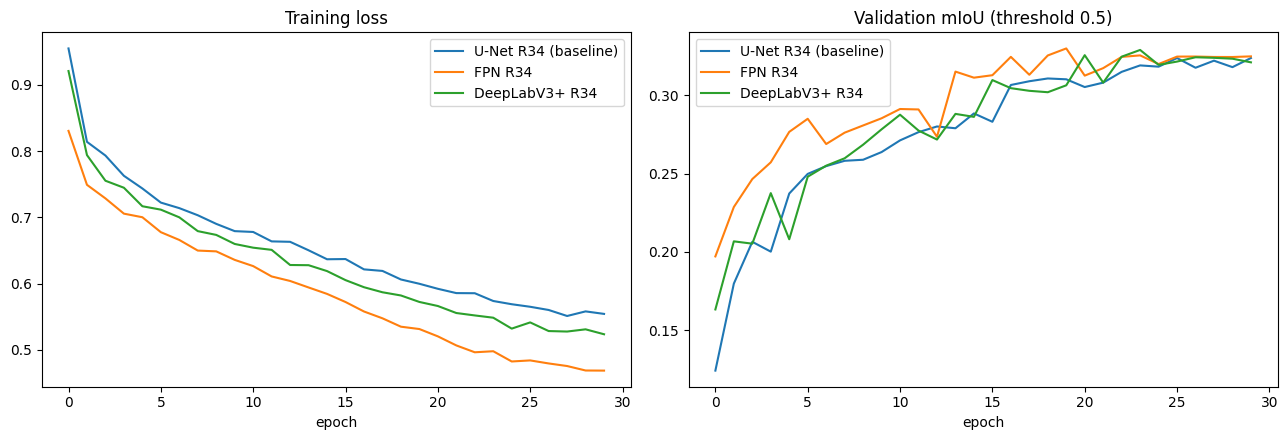

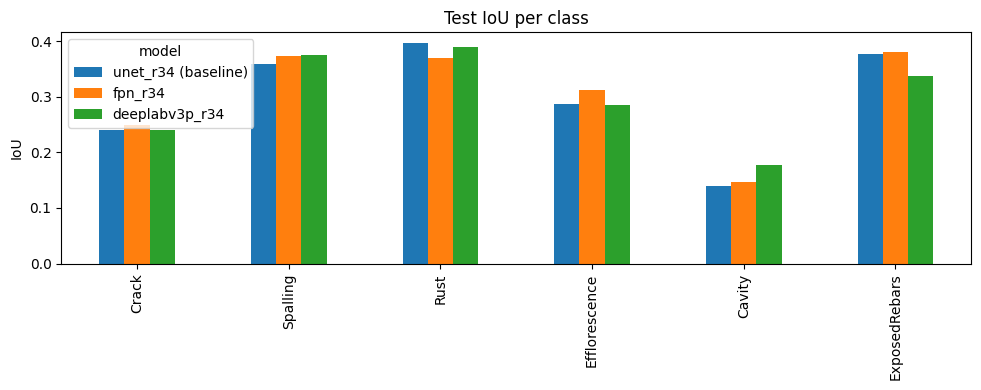

In [ ]:
FIG = EXP_ROOT/"figures"; FIG.mkdir(parents=True, exist_ok=True)

rows = [dict(model="unet_r34 (baseline)", val=0.326, test=0.300, min_epoch=3.5, params=24.4,
             Crack=0.241, Spalling=0.359, Rust=0.396, Efflorescence=0.287, Cavity=0.139, ExposedRebars=0.377)]
for name, label in [("fpn", "fpn_r34"), ("deeplab", "deeplabv3p_r34")]:
    r = res[name]
    rows.append(dict(model=label, val=r.get("val_miou_tuned"), test=r.get("test_miou_tuned"),
                     min_epoch=r.get("minutes_per_epoch"), params=r.get("params_millions"),
                     **r.get("test_iou_per_class", {})))
cmp = pd.DataFrame(rows)
print(cmp.round(3).to_string(index=False))
cmp.to_csv(FIG/"model_comparison.csv", index=False)

H = {"U-Net R34 (baseline)": pd.read_csv(BASE/"history.csv"),
     "FPN R34": pd.read_csv(BASE/"history_fpn.csv"),
     "DeepLabV3+ R34": pd.read_csv(BASE/"history_deeplab.csv")}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for n, h in H.items():
    ax[0].plot(h.epoch, h.train_loss, label=n); ax[1].plot(h.epoch, h.val_miou, label=n)
ax[0].set_title("Training loss"); ax[1].set_title("Validation mIoU (threshold 0.5)")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(FIG/"model_curves.png", dpi=150); plt.show()

cmp.set_index("model")[TARGET].T.plot(kind="bar", figsize=(10, 4))
plt.title("Test IoU per class"); plt.ylabel("IoU"); plt.tight_layout()
plt.savefig(FIG/"per_class_test_iou.png", dpi=150); plt.show()

Chosen thresholds per class:
                     Crack  Spalling  Rust  Efflorescence  Cavity  ExposedRebars
unet_r34 (baseline)    0.7       0.2   0.1            0.3     0.6            0.1
fpn_r34                0.7       0.4   0.2            0.8     0.1            0.1
deeplabv3p_r34         0.7       0.3   0.3            0.8     0.4            0.1

mIoU with threshold 0.5 vs tuned thresholds:
                     val_050  val_tuned  test_050  test_tuned
model                                                        
unet_r34 (baseline)    0.324      0.326     0.299       0.300
fpn_r34                0.330      0.339     0.311       0.306
deeplabv3p_r34         0.329      0.333     0.304       0.301


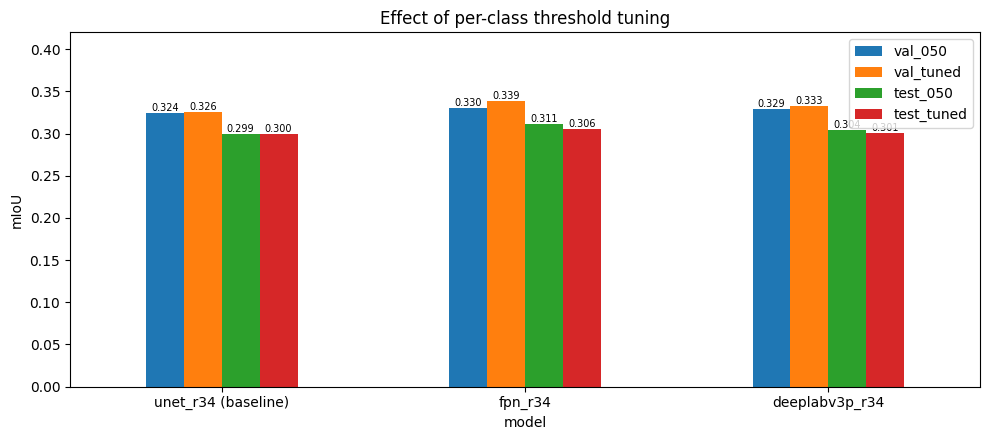

In [ ]:
FIG = EXP_ROOT/"figures"; FIG.mkdir(parents=True, exist_ok=True)

thr_tbl = pd.DataFrame({
    "unet_r34 (baseline)": json.load(open(BASE/"best_thresholds.json")),
    "fpn_r34": res["fpn"]["thresholds"],
    "deeplabv3p_r34": res["deeplab"]["thresholds"]}).T[TARGET]
print("Chosen thresholds per class:"); print(thr_tbl.round(2).to_string())
thr_tbl.to_csv(FIG/"chosen_thresholds.csv")

gain = pd.DataFrame([
    dict(model="unet_r34 (baseline)", val_050=0.324, val_tuned=0.326, test_050=0.299, test_tuned=0.300),
    dict(model="fpn_r34", val_050=res["fpn"].get("val_miou_thr050"), val_tuned=res["fpn"].get("val_miou_tuned"),
         test_050=res["fpn"].get("test_miou_thr050"), test_tuned=res["fpn"].get("test_miou_tuned")),
    dict(model="deeplabv3p_r34", val_050=res["deeplab"].get("val_miou_thr050"), val_tuned=res["deeplab"].get("val_miou_tuned"),
         test_050=res["deeplab"].get("test_miou_thr050"), test_tuned=res["deeplab"].get("test_miou_tuned"))]).set_index("model")
print("\nmIoU with threshold 0.5 vs tuned thresholds:"); print(gain.round(3).to_string())
gain.to_csv(FIG/"threshold_gain.csv")

ax = gain.plot(kind="bar", figsize=(10, 4.5), ylim=(0, 0.42))
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7)
ax.set_ylabel("mIoU"); ax.set_title("Effect of per-class threshold tuning"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG/"threshold_gain.png", dpi=150); plt.show()

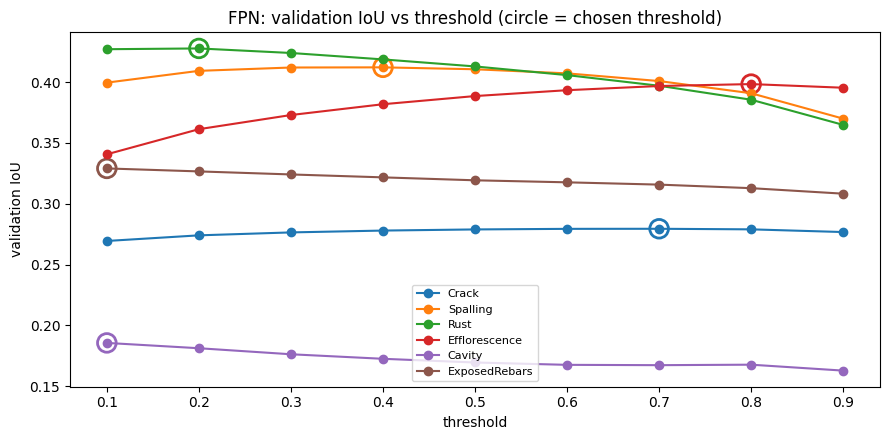

In [ ]:
ths = np.arange(0.1, 0.91, 0.1)
curve = np.array([evaluate(model, val_dl, thr=float(t))["iou"] for t in ths])   # shape (9, 6)

fig, ax = plt.subplots(figsize=(9, 4.5))
for c, name in enumerate(TARGET):
    line, = ax.plot(ths, curve[:, c], marker="o", label=name)
    j = int(np.argmin(np.abs(ths - best_thr[c])))
    ax.scatter([ths[j]], [curve[j, c]], s=180, facecolors="none", edgecolors=line.get_color(), linewidths=2)
ax.set_xlabel("threshold"); ax.set_ylabel("validation IoU")
ax.set_title("FPN: validation IoU vs threshold (circle = chosen threshold)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG/"fpn_threshold_curves.png", dpi=150); plt.show()

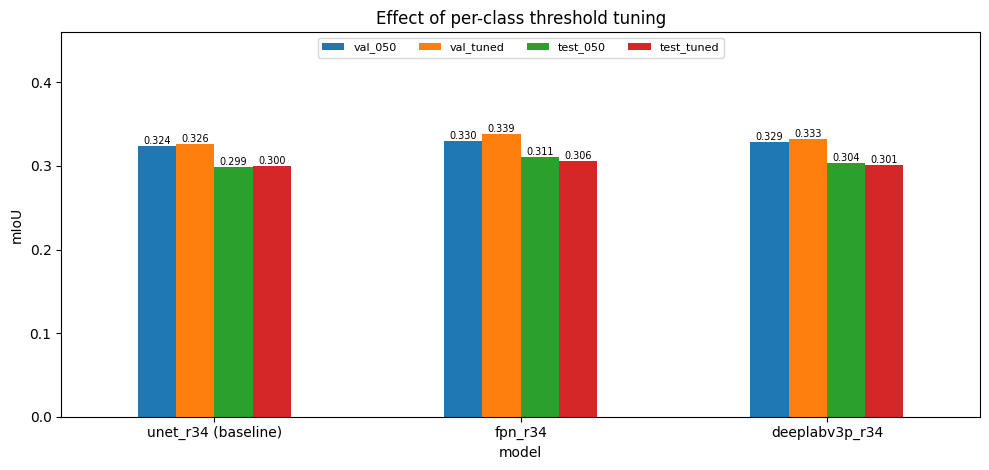

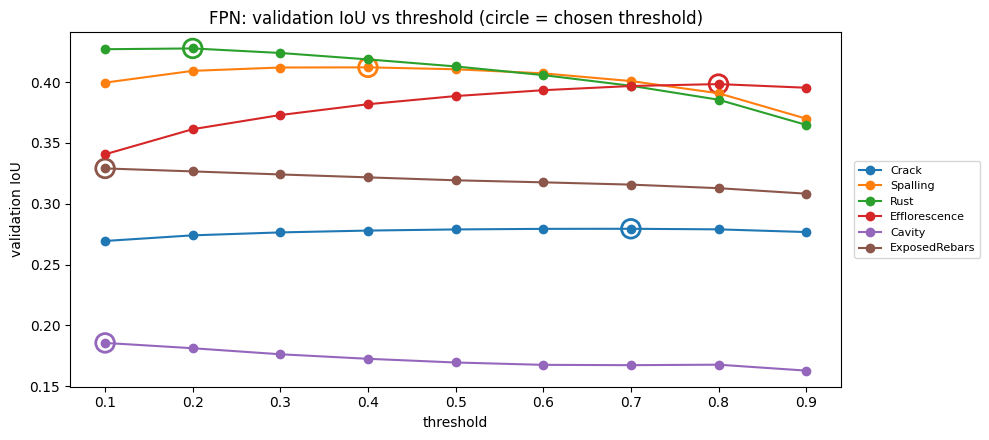

In [ ]:
ax = gain.plot(kind="bar", figsize=(10, 4.8), ylim=(0, 0.46))
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=7)
ax.legend(ncol=4, loc="upper center", fontsize=8)
ax.set_ylabel("mIoU"); ax.set_title("Effect of per-class threshold tuning"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(FIG/"threshold_gain.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for c, name in enumerate(TARGET):
    line, = ax.plot(ths, curve[:, c], marker="o", label=name)
    j = int(np.argmin(np.abs(ths - best_thr[c])))
    ax.scatter([ths[j]], [curve[j, c]], s=180, facecolors="none", edgecolors=line.get_color(), linewidths=2)
ax.set_xlabel("threshold"); ax.set_ylabel("validation IoU")
ax.set_title("FPN: validation IoU vs threshold (circle = chosen threshold)")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.tight_layout(); plt.savefig(FIG/"fpn_threshold_curves.png", dpi=150, bbox_inches="tight"); plt.show()

severety grading

In [ ]:
from skimage.morphology import skeletonize

AREA_CUTS = {"Spalling": (0.01, 0.05), "Rust": (0.02, 0.08), "Efflorescence": (0.03, 0.10),
             "Cavity": (0.005, 0.02), "ExposedRebars": (0.002, 0.01)}
MIN_PX = {"Crack": 20, "Spalling": 150, "Rust": 150, "Efflorescence": 150, "Cavity": 15, "ExposedRebars": 60}
STRUCTURAL = {"Crack", "Spalling", "Cavity", "ExposedRebars"}   # these can reach grade 3
LEVELS = ["None", "Minor", "Moderate", "Severe"]

def clean_mask(m, min_px):
    n, lab_, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    out = np.zeros(m.shape, np.uint8)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= min_px: out[lab_ == i] = 1
    return out

def grade(v, cuts): return 0 if v <= 0 else 1 if v < cuts[0] else 2 if v < cuts[1] else 3

def crack_metrics(m):
    if m.sum() == 0: return 0.0, 0.0
    skel = skeletonize(m > 0)
    dist = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 3)
    length = skel.sum()
    width = 2 * dist[skel].mean() if length else 0.0
    return length / SIZE, width

def severity_report(masks):               # masks: (6,H,W) binary arrays
    rep, contrib = {}, []
    for c, name in enumerate(TARGET):
        m = clean_mask(masks[c], MIN_PX[name])
        ratio = m.mean()
        if name == "Crack":
            L, W = crack_metrics(m)
            g = grade(L, (0.3, 1.0))
            if g > 0 and W > 6: g = min(3, g + 1)
            rep[name] = dict(level=LEVELS[g], grade=g, length_ratio=round(float(L), 3), mean_width_px=round(float(W), 1))
        else:
            g = grade(ratio, AREA_CUTS[name])
            rep[name] = dict(level=LEVELS[g], grade=g, area_pct=round(float(ratio) * 100, 2))
        contrib.append(g if name in STRUCTURAL else min(g, 2))
    overall = max(contrib)
    rep["OVERALL"] = dict(grade=overall, condition=["Good", "Fair", "Poor", "Critical"][overall])
    return rep

In [ ]:
FIG = EXP_ROOT/"figures"; FIG.mkdir(parents=True, exist_ok=True)
ds_test = DaclDataset("test", tf_val)

def predict_masks(k):
    x, y = ds_test[k]
    with torch.no_grad():
        p = torch.sigmoid(model(x[None].to(DEV)))[0].cpu().numpy()
    masks = (p > np.array(best_thr)[:, None, None]).astype(np.uint8)
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{ds_test.ids[k]}.jpg")), cv2.COLOR_BGR2RGB)
    return img, masks, y.numpy().astype(np.uint8)

random.seed(7)
ks = random.sample(range(len(ds_test)), 12)
rows = []
fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, k in zip(axes.ravel(), ks):
    img, pm, gm = predict_masks(k)
    rp, rg = severity_report(pm), severity_report(gm)
    rows.append({"img": k, **{f"pred_{t}": rp[t]["grade"] for t in TARGET},
                 "pred_overall": rp["OVERALL"]["condition"], "gt_overall": rg["OVERALL"]["condition"]})
    ov = img.copy()
    for c in range(NC): ov[pm[c] > 0] = COLORS[c]
    ax.imshow(cv2.addWeighted(img, .55, ov, .45, 0)); ax.axis("off")
    ax.set_title(f"#{k}  pred: {rp['OVERALL']['condition']} | GT: {rg['OVERALL']['condition']}", fontsize=10)
plt.tight_layout(); plt.savefig(FIG/"severity_examples.png", dpi=110); plt.show()

sev = pd.DataFrame(rows)
print(sev.to_string(index=False))
sev.to_csv(FIG/"severity_examples.csv", index=False)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
rows = []
for k in ks:
    img, pm, gm = predict_masks(k)
    rp, rg = severity_report(pm), severity_report(gm)
    rows.append(dict(img=k,
        crack_len_pred=rp["Crack"]["length_ratio"], crack_w_pred=rp["Crack"]["mean_width_px"], crack_g_pred=rp["Crack"]["grade"],
        crack_len_gt=rg["Crack"]["length_ratio"],   crack_w_gt=rg["Crack"]["mean_width_px"],   crack_g_gt=rg["Crack"]["grade"],
        cav_pct_pred=rp["Cavity"]["area_pct"], cav_g_pred=rp["Cavity"]["grade"], cav_g_gt=rg["Cavity"]["grade"]))
print(pd.DataFrame(rows).to_string(index=False))

 img  crack_len_pred  crack_w_pred  crack_g_pred  crack_len_gt  crack_w_gt  crack_g_gt  cav_pct_pred  cav_g_pred  cav_g_gt
 331           0.412           8.2             3         0.000         0.0           0          5.29           3         1
 970           0.000           0.0             0         0.000         0.0           0          0.36           1         0
 154           0.000           0.0             0         0.000         0.0           0          0.00           0         0
 404           0.584          10.2             3         0.715         9.4           3          0.15           1         0
 666           0.000           0.0             0         0.000         0.0           0          0.00           0         0
  49           0.512           6.8             3         0.826         6.0           2          0.00           0         0
  74           0.000           0.0             0         0.000         0.0           0          0.03           1         1
 840           0

In [ ]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix

t0 = time.time()
g_pred, g_gt = [], []
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        p = torch.sigmoid(model(x.to(DEV))).cpu().numpy()
        pm = (p > np.array(best_thr)[None, :, None, None]).astype(np.uint8)
        gm = y.numpy().astype(np.uint8)
        for i in range(len(x)):
            g_pred.append(severity_report(pm[i])["OVERALL"]["grade"])
            g_gt.append(severity_report(gm[i])["OVERALL"]["grade"])
g_pred, g_gt = np.array(g_pred), np.array(g_gt)

names = ["Good", "Fair", "Poor", "Critical"]
print(f"images: {len(g_pred)} | time: {(time.time()-t0)/60:.1f} min")
print("exact agreement :", round(float((g_pred == g_gt).mean()), 3))
print("within 1 level  :", round(float((abs(g_pred - g_gt) <= 1).mean()), 3))
print("weighted kappa  :", round(float(cohen_kappa_score(g_gt, g_pred, weights="quadratic")), 3))
print("over-graded     :", round(float((g_pred > g_gt).mean()), 3), "| under-graded:", round(float((g_pred < g_gt).mean()), 3))
cm = pd.DataFrame(confusion_matrix(g_gt, g_pred, labels=[0, 1, 2, 3]),
                  index=[f"GT {n}" for n in names], columns=[f"pred {n}" for n in names])
print(cm)
cm.to_csv(FIG/"severity_confusion_matrix.csv")

images: 975 | time: 0.9 min
exact agreement : 0.547
within 1 level  : 0.882
weighted kappa  : 0.564
over-graded     : 0.253 | under-graded: 0.2
             pred Good  pred Fair  pred Poor  pred Critical
GT Good             63         73         34             20
GT Fair             15         82         36             21
GT Poor             14         62        186             63
GT Critical          5         21         78            202


In [ ]:
AREA_NAMES = ["Spalling", "Rust", "Efflorescence", "Cavity", "ExposedRebars"]

def measures(masks):
    out = {}
    for c, name in enumerate(TARGET):
        m = clean_mask(masks[c], MIN_PX[name])
        if name == "Crack": out["crack_L"], out["crack_W"] = crack_metrics(m)
        else:               out[name] = float(m.mean())
    return out

def overall_grade(me, bump_w=6, floor_frac=0.0):
    g = grade(me["crack_L"], (0.3, 1.0))
    if g > 0 and bump_w is not None and me["crack_W"] > bump_w: g = min(3, g + 1)
    contrib = [g]                                           # crack counts as structural
    for name in AREA_NAMES:
        v = me[name]
        gg = 0 if v < floor_frac * AREA_CUTS[name][0] else grade(v, AREA_CUTS[name])
        contrib.append(gg if name in STRUCTURAL else min(gg, 2))
    return max(contrib)

def collect(loader):
    P, G = [], []
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            p = torch.sigmoid(model(x.to(DEV))).cpu().numpy()
            pm = (p > np.array(best_thr)[None, :, None, None]).astype(np.uint8)
            gm = y.numpy().astype(np.uint8)
            for i in range(len(x)):
                P.append(measures(pm[i])); G.append(measures(gm[i]))
    return P, G

t0 = time.time()
P_val, G_val = collect(val_dl)
print(len(P_val), "validation images measured |", round((time.time() - t0) / 60, 1), "min")

582 validation images measured | 0.6 min


In [ ]:
from sklearn.metrics import cohen_kappa_score

rows = []
for bump in [None, 6, 8, 10, 12]:
    for fl in [0.0, 0.25, 0.5, 1.0]:
        gp = np.array([overall_grade(m, bump, fl) for m in P_val])
        gg = np.array([overall_grade(m, bump, fl) for m in G_val])
        rows.append(dict(width_bump_px=bump, floor_frac=fl,
                         kappa=round(float(cohen_kappa_score(gg, gp, weights="quadratic")), 3),
                         exact=round(float((gp == gg).mean()), 3),
                         within1=round(float((abs(gp - gg) <= 1).mean()), 3),
                         over=round(float((gp > gg).mean()), 3), under=round(float((gp < gg).mean()), 3),
                         pct_Good_gt=round(float((gg == 0).mean()), 2), pct_Critical_gt=round(float((gg == 3).mean()), 2)))
grid = pd.DataFrame(rows).sort_values("kappa", ascending=False)
print(grid.to_string(index=False))
grid.to_csv(FIG/"severity_rule_search_val.csv", index=False)

 width_bump_px  floor_frac  kappa  exact  within1  over  under  pct_Good_gt  pct_Critical_gt
           6.0        0.25  0.514  0.581    0.859 0.189  0.230         0.08             0.37
           NaN        0.25  0.505  0.564    0.876 0.187  0.249         0.08             0.28
          10.0        0.25  0.503  0.553    0.864 0.208  0.239         0.08             0.32
          12.0        0.25  0.498  0.555    0.868 0.192  0.253         0.08             0.31
           6.0        0.50  0.496  0.593    0.832 0.192  0.215         0.14             0.37
           8.0        0.25  0.495  0.558    0.856 0.211  0.230         0.08             0.33
           6.0        0.00  0.489  0.577    0.895 0.199  0.223         0.03             0.37
           NaN        0.50  0.487  0.576    0.844 0.191  0.234         0.14             0.28
          10.0        0.50  0.485  0.565    0.835 0.211  0.223         0.14             0.32
          12.0        0.50  0.480  0.567    0.837 0.196  0.237        

In [ ]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix

FLOOR_FRAC, BUMP_W = 0.25, 6        # FROZEN from the validation search. Don't change after this.

P_test, G_test = collect(test_dl)
gp_new = np.array([overall_grade(m, BUMP_W, FLOOR_FRAC) for m in P_test])
gg_new = np.array([overall_grade(m, BUMP_W, FLOOR_FRAC) for m in G_test])
gp_old = np.array([overall_grade(m, 6, 0.0) for m in P_test])
gg_old = np.array([overall_grade(m, 6, 0.0) for m in G_test])

def summary(gp, gg, label):
    print(f"{label:>10} | kappa {cohen_kappa_score(gg, gp, weights='quadratic'):.3f} | exact {(gp == gg).mean():.3f} | "
          f"within1 {(abs(gp - gg) <= 1).mean():.3f} | over {(gp > gg).mean():.3f} | under {(gp < gg).mean():.3f} | GT Good share {(gg == 0).mean():.2f}")
summary(gp_old, gg_old, "old rule")
summary(gp_new, gg_new, "new rule")

names = ["Good", "Fair", "Poor", "Critical"]
cm = pd.DataFrame(confusion_matrix(gg_new, gp_new, labels=[0, 1, 2, 3]),
                  index=[f"GT {n}" for n in names], columns=[f"pred {n}" for n in names])
print(cm); cm.to_csv(FIG/"severity_confusion_matrix_final.csv")

json.dump(dict(FLOOR_FRAC=FLOOR_FRAC, BUMP_W=BUMP_W, AREA_CUTS=AREA_CUTS, MIN_PX=MIN_PX, CRACK_LENGTH_CUTS=[0.3, 1.0]),
          open(FIG/"severity_rules_final.json", "w"), indent=2)

  old rule | kappa 0.564 | exact 0.547 | within1 0.882 | over 0.253 | under 0.200 | GT Good share 0.19
  new rule | kappa 0.565 | exact 0.562 | within1 0.841 | over 0.230 | under 0.208 | GT Good share 0.25
             pred Good  pred Fair  pred Poor  pred Critical
GT Good            122         50         45             24
GT Fair             23         38         25             17
GT Poor             43         33        186             63
GT Critical         14         12         78            202


In [ ]:
RATE = EXP_ROOT/"rating"; (RATE/"images").mkdir(parents=True, exist_ok=True)
ds_test = DaclDataset("test", tf_val)            # same order as test_dl (sorted, not shuffled)

rng = np.random.default_rng(2026)
chosen = []
for g in range(4):                                # up to 13 images per predicted grade
    idx = np.where(gp_new == g)[0]
    chosen += list(rng.choice(idx, size=min(13, len(idx)), replace=False))
chosen = [int(k) for k in rng.permutation(chosen)[:50]]
print("images chosen:", len(chosen))

key = []
for n, k in enumerate(chosen, start=1):
    rid = f"r{n:02d}"
    im = cv2.imread(str(PROC/"test"/"img"/f"{ds_test.ids[k]}.jpg"))
    cv2.imwrite(str(RATE/"images"/f"{rid}.jpg"), im)
    key.append(dict(img_id=rid, test_index=k, file=ds_test.ids[k],
                    model_grade=names[gp_new[k]], model_grade_oldrule=names[gp_old[k]], gt_grade=names[gg_new[k]]))
pd.DataFrame(key).to_csv(FIG/"rating_key_DO_NOT_SHARE.csv", index=False)
pd.DataFrame({"img_id": [f"r{n:02d}" for n in range(1, len(chosen) + 1)], "Namitha": "", "Jeevani": "", "Gouthami": "", "Vishnu": ""}
             ).to_csv(RATE/"rating_template.csv", index=False)
print("saved to:", RATE)

images chosen: 50
saved to: /content/drive/MyDrive/bridge_experiments/rating


In [ ]:
import itertools, numpy as np, pandas as pd
from sklearn.metrics import cohen_kappa_score, confusion_matrix
!pip install -q krippendorff
import krippendorff

names = ["Good","Fair","Poor","Critical"]; m = {n.lower():i for i,n in enumerate(names)}
raters = ["Namitha","Jeevani","Gouthami","Vishnu"]
r = pd.read_csv(EXP_ROOT/"rating"/"rating_template.csv")
for c in raters: r[c] = r[c].str.strip().str.lower().map(m)
key = pd.read_csv(FIG/"rating_key_DO_NOT_SHARE.csv")
df = r.merge(key, on="img_id")
for c in ["model_grade","gt_grade"]: df[c] = df[c].str.lower().map(m)
assert df[raters].notna().all().all()          # catches typos like "criticle"

# human consensus = median of 4 raters; ties round UP (conservative for safety)
df["consensus"] = np.floor(df[raters].median(axis=1) + 0.5).astype(int)

AttributeError: Can only use .str accessor with string values!

In [ ]:
qwk = lambda a,b: cohen_kappa_score(a,b,weights="quadratic")
hh = [qwk(df[a],df[b]) for a,b in itertools.combinations(raters,2)]
print("human-human QWK mean:", np.mean(hh).round(3), "range", np.min(hh).round(2), np.max(hh).round(2))
print("Krippendorff alpha:", krippendorff.alpha(reliability_data=df[raters].T.values, level_of_measurement="ordinal").round(3))

human-human QWK mean: 0.494 range 0.29 0.66
Krippendorff alpha: 0.511


In [ ]:
import pandas as pd, itertools
pm = pd.DataFrame(index=raters, columns=raters, dtype=float)
for a,b in itertools.product(raters, raters):
    pm.loc[a,b] = 1.0 if a==b else qwk(df[a], df[b])
print(pm.round(2))
print(df[raters].apply(lambda s: s.value_counts(normalize=True)).T.round(2))  # grade distribution per rater

          Namitha  Jeevani  Gouthami  Vishnu
Namitha      1.00     0.59      0.66    0.42
Jeevani      0.59     1.00      0.61    0.29
Gouthami     0.66     0.61      1.00    0.41
Vishnu       0.42     0.29      0.41    1.00
             0     1     2     3
Namitha   0.30  0.26  0.32  0.12
Jeevani   0.28  0.26  0.26  0.20
Gouthami  0.22  0.36  0.26  0.16
Vishnu    0.16  0.34  0.42  0.08


In [ ]:
mh = [qwk(df[c], df["model_grade"]) for c in raters]
print("model vs each rater:", np.round(mh,3), "mean", np.mean(mh).round(3))

# leave-one-out: each person vs median of the other three, and model vs the same
loo_h, loo_m = [], []
for c in raters:
    others = [x for x in raters if x != c]
    cons = np.floor(df[others].median(axis=1)+0.5).astype(int)
    loo_h.append(qwk(df[c], cons)); loo_m.append(qwk(df["model_grade"], cons))
print("human vs rest:", np.mean(loo_h).round(3), "| model vs rest:", np.mean(loo_m).round(3))
print("model vs consensus exact:", (df.model_grade==df.consensus).mean(),
      "within1:", (abs(df.model_grade-df.consensus)<=1).mean())
print("GT-rule vs consensus:", qwk(df.gt_grade, df.consensus).round(3))
print(pd.DataFrame(confusion_matrix(df.consensus, df.model_grade, labels=[0,1,2,3]), index=names, columns=names))

model vs each rater: [0.287 0.443 0.292 0.43 ] mean 0.363
human vs rest: 0.574 | model vs rest: 0.345
model vs consensus exact: 0.32 within1: 0.82
GT-rule vs consensus: 0.237
          Good  Fair  Poor  Critical
Good         4     3     0         1
Fair         5     7     3         3
Poor         4     2     5         7
Critical     0     1     5         0


In [ ]:
rng = np.random.default_rng(0); bs=[]
for _ in range(2000):
    s = df.sample(len(df), replace=True, random_state=int(rng.integers(1e9)))
    bs.append(qwk(s.model_grade, s.consensus))
print(np.percentile(bs,[2.5,97.5]).round(3))

[0.121 0.543]


In [ ]:
def features(masks, probs=None):
    f = {}
    for c, name in enumerate(TARGET):
        m = clean_mask(masks[c], MIN_PX[name])
        f[name+"_area"] = m.mean()
        n, _, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        f[name+"_ncomp"] = n-1
        f[name+"_maxcomp"] = (st[1:, cv2.CC_STAT_AREA].max()/m.size) if n > 1 else 0
        if probs is not None: f[name+"_meanprob"] = probs[c][m > 0].mean() if m.any() else 0
    L, W = crack_metrics(clean_mask(masks[0], MIN_PX["Crack"]))
    f["crack_len"], f["crack_w"] = L, W
    return f

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import cohen_kappa_score

# 1) features from the PREDICTED masks of the 50 rated images
def features(masks):
    f = {}
    for c, name in enumerate(TARGET):
        m = clean_mask(masks[c], MIN_PX[name])
        f[name + "_area"] = float(m.mean())
    L, W = crack_metrics(clean_mask(masks[0], MIN_PX["Crack"]))
    f["crack_len"], f["crack_w"] = float(L), float(W)
    return f

rows = []
for _, row in df.iterrows():
    img, pm, gm = predict_masks(int(row.test_index))   # defined in your severity cell
    rows.append(features(pm))
X = pd.DataFrame(rows)
y = df["consensus"].values

print(X.shape, np.bincount(y, minlength=4))   # check class counts

# 2) cross-validated prediction (3 folds, because Critical has only 6 images)
qwk = lambda a, b: cohen_kappa_score(a, b, weights="quadratic")
cv = StratifiedKFold(3, shuffle=True, random_state=0)
tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0)
pred = cross_val_predict(tree, X, y, cv=cv)

print("learned tree  QWK:", round(qwk(y, pred), 3), "| exact:", (pred == y).mean())
print("current rules QWK:", round(qwk(y, df.model_grade.values), 3), "| exact:", (df.model_grade.values == y).mean())
print("Critical recall:", ((pred == 3) & (y == 3)).sum(), "/", (y == 3).sum())

(50, 8) [ 8 18 18  6]
learned tree  QWK: 0.315 | exact: 0.38
current rules QWK: 0.344 | exact: 0.32
Critical recall: 2 / 6


In [ ]:
RATE2 = EXP_ROOT/"rating2"; (RATE2/"images").mkdir(parents=True, exist_ok=True)

done = set(pd.read_csv(FIG/"rating_key_DO_NOT_SHARE.csv")["test_index"])
pool = [k for k in range(len(ds_test)) if k not in done]
rng = np.random.default_rng(777)
chosen2 = [int(k) for k in rng.choice(pool, size=120, replace=False)]

key2 = []
for n, k in enumerate(chosen2, start=1):
    rid = f"s{n:03d}"
    im = cv2.imread(str(PROC/"test"/"img"/f"{ds_test.ids[k]}.jpg"))
    cv2.imwrite(str(RATE2/"images"/f"{rid}.jpg"), im)
    key2.append(dict(img_id=rid, test_index=k, file=ds_test.ids[k]))
pd.DataFrame(key2).to_csv(FIG/"rating2_key_DO_NOT_SHARE.csv", index=False)   # no model grades in the key file
pd.DataFrame({"img_id":[d["img_id"] for d in key2], "Namitha":"","Jeevani":"","Gouthami":"","Vishnu":""}
             ).to_csv(RATE2/"rating2_template.csv", index=False)
print("saved to", RATE2)

saved to /content/drive/MyDrive/bridge_experiments/rating2


In [ ]:
r2 = pd.read_csv(RATE2/"rating2_template.csv")
for c in raters: r2[c] = r2[c].str.strip().str.lower().map(m)
assert r2[raters].notna().all().all()
df2 = r2.merge(pd.read_csv(FIG/"rating2_key_DO_NOT_SHARE.csv"), on="img_id")
df2["consensus"] = np.floor(df2[raters].median(axis=1) + 0.5).astype(int)
print(np.bincount(df2.consensus, minlength=4))
hh = [qwk(df2[a], df2[b]) for a, b in itertools.combinations(raters, 2)]
print("human-human QWK:", np.mean(hh).round(3))

NameError: name 'raters' is not defined

In [ ]:
# ===== SELF-CONTAINED: setup + rating2 analysis =====
import os, json, itertools, warnings
warnings.filterwarnings("ignore")
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")
os.system("pip install -q segmentation-models-pytorch opencv-python-headless scikit-image krippendorff")
if not os.path.exists("/content/processed"):
    os.system("unzip -q /content/drive/MyDrive/bridge_project/processed.zip -d /content/")

from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import segmentation_models_pytorch as smp
import krippendorff
from skimage.morphology import skeletonize
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---- paths (EDIT IF NEEDED) ----
PROC = Path("/content/processed")
BASE = Path("/content/drive/MyDrive/bridge_project")
EXP_ROOT = Path("/content/drive/MyDrive/bridge_experiments")
RATING_CSV = EXP_ROOT/"rating2"/"rating2.csv"
KEY_CSV = EXP_ROOT/"figures"/"rating2_key_DO_NOT_SHARE.csv"

TARGET = ["Crack","Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]
NC, SIZE = 6, 512
DEV = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = np.array([0.485,0.456,0.406]), np.array([0.229,0.224,0.225])
names = ["Good","Fair","Poor","Critical"]; lab = {n.lower(): i for i, n in enumerate(names)}
raters = ["Namitha","Jeevani","Gouthami","Vishnu"]
qwk = lambda a, b: cohen_kappa_score(a, b, weights="quadratic")

# ---- model + thresholds ----
res = json.load(open(BASE/"results_fpn.json"))
best_thr = np.array([res["thresholds"][t] for t in TARGET])
model = smp.FPN(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
model.load_state_dict(torch.load(BASE/"best_fpn.pth", map_location=DEV)); model.eval()
test_ids = sorted(p.stem for p in (PROC/"test"/"img").glob("*.jpg"))

def predict_masks(k):
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg")), cv2.COLOR_BGR2RGB)
    x = torch.from_numpy(((img/255.0 - MEAN)/STD).transpose(2,0,1)).float()[None].to(DEV)
    with torch.no_grad(), torch.autocast("cuda", enabled=(DEV=="cuda")):
        p = torch.sigmoid(model(x))[0].float().cpu().numpy()
    return (p > best_thr[:,None,None]).astype(np.uint8)

# ---- severity rules (frozen: floor 0.25, width bump 6) ----
AREA_CUTS = {"Spalling":(0.01,0.05),"Rust":(0.02,0.08),"Efflorescence":(0.03,0.10),
             "Cavity":(0.005,0.02),"ExposedRebars":(0.002,0.01)}
MIN_PX = {"Crack":20,"Spalling":150,"Rust":150,"Efflorescence":150,"Cavity":15,"ExposedRebars":60}
STRUCTURAL = {"Crack","Spalling","Cavity","ExposedRebars"}
AREA_NAMES = ["Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]

def clean_mask(m, min_px):
    n, lb, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    out = np.zeros(m.shape, np.uint8)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= min_px: out[lb == i] = 1
    return out
def grade(v, cuts): return 0 if v <= 0 else 1 if v < cuts[0] else 2 if v < cuts[1] else 3
def crack_metrics(m):
    if m.sum() == 0: return 0.0, 0.0
    skel = skeletonize(m > 0); dist = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 3)
    L = skel.sum(); return L/SIZE, (2*dist[skel].mean() if L else 0.0)
def measures(masks):
    out = {}
    for c, name in enumerate(TARGET):
        mm = clean_mask(masks[c], MIN_PX[name])
        if name == "Crack": out["crack_L"], out["crack_W"] = crack_metrics(mm)
        else: out[name] = float(mm.mean())
    return out
def overall_grade(me, bump_w=6, floor_frac=0.25):
    g = grade(me["crack_L"], (0.3, 1.0))
    if g > 0 and me["crack_W"] > bump_w: g = min(3, g+1)
    contrib = [g]
    for n in AREA_NAMES:
        v = me[n]; gg = 0 if v < floor_frac*AREA_CUTS[n][0] else grade(v, AREA_CUTS[n])
        contrib.append(gg if n in STRUCTURAL else min(gg, 2))
    return max(contrib)
def features(masks):
    f = {}
    for c, n in enumerate(TARGET):
        f[n+"_area"] = float(clean_mask(masks[c], MIN_PX[n]).mean())
    L, W = crack_metrics(clean_mask(masks[0], MIN_PX["Crack"]))
    f["crack_len"], f["crack_w"] = float(L), float(W)
    return f

# ---- load rating2 ----
r = pd.read_csv(RATING_CSV)
for c in raters: r[c] = r[c].astype(str).str.strip().str.lower().map(lab)
bad = r[r[raters].isna().any(axis=1)]
print("rows with missing/misspelled grades:", len(bad)); print(bad.head())
r = r.dropna(subset=raters).copy(); r[raters] = r[raters].astype(int)
df = r.merge(pd.read_csv(KEY_CSV)[["img_id","test_index"]], on="img_id")
df["consensus"] = np.floor(df[raters].median(axis=1) + 0.5).astype(int)
y = df.consensus.values
print("images:", len(df), "| consensus counts [G,F,P,C]:", np.bincount(y, minlength=4))

# ---- human agreement ----
hh = [qwk(df[a], df[b]) for a, b in itertools.combinations(raters, 2)]
print("\nhuman-human QWK mean:", round(np.mean(hh),3), "range", round(min(hh),2), round(max(hh),2))
print("Krippendorff alpha:", round(krippendorff.alpha(reliability_data=df[raters].T.values, level_of_measurement="ordinal"),3))
print(df[raters].apply(lambda s: s.value_counts(normalize=True)).T.fillna(0).round(2))

# ---- features + rule grade for all images (cached) ----
cache = EXP_ROOT/"rating2"/"features_cache.csv"
rows = []
for k in df.test_index:
    pm = predict_masks(int(k)); f = features(pm); f["rule_grade"] = overall_grade(measures(pm)); rows.append(f)
X = pd.DataFrame(rows); X.to_csv(cache, index=False)
rule = X.pop("rule_grade").values

# ---- rules vs humans (rules are not fitted, so all images are fair to use) ----
loo_h, loo_m = [], []
for c in raters:
    cons = np.floor(df[[x for x in raters if x != c]].median(axis=1) + 0.5).astype(int)
    loo_h.append(qwk(df[c], cons)); loo_m.append(qwk(rule, cons))
print("\nhuman vs rest:", round(np.mean(loo_h),3), "| rule-model vs rest:", round(np.mean(loo_m),3))
print("rules vs consensus: QWK", round(qwk(y, rule),3), "| exact", round((rule==y).mean(),3),
      "| within1", round((abs(rule-y)<=1).mean(),3))
print(pd.DataFrame(confusion_matrix(y, rule, labels=[0,1,2,3]), index=names, columns=names))

# ---- learned grader: dev/holdout split ----
idx = np.arange(len(y))
try: dev, hold = train_test_split(idx, test_size=40, stratify=y, random_state=42)
except ValueError: dev, hold = train_test_split(idx, test_size=40, random_state=42)
Xd, yd = X.iloc[dev], y[dev]
nsp = max(2, min(5, int(np.bincount(yd, minlength=4)[np.bincount(yd, minlength=4) > 0].min())))
cands = {
 "tree_d3": DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0),
 "tree_d4": DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=0),
 "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
 "forest": RandomForestClassifier(200, max_depth=4, class_weight="balanced", random_state=0)}
print(f"\ndev CV ({nsp}-fold x5 seeds), dev={len(dev)}, holdout={len(hold)}")
scores = {}
for n, mdl in cands.items():
    q = [qwk(yd, cross_val_predict(mdl, Xd, yd, cv=StratifiedKFold(nsp, shuffle=True, random_state=s))) for s in range(5)]
    scores[n] = np.mean(q); print(f"{n:8s} QWK {np.mean(q):.3f} +- {np.std(q):.3f}")
print("rules (dev) QWK", round(qwk(yd, rule[dev]),3))
winner = max(scores, key=scores.get); print("winner by dev-CV:", winner)

# ---- holdout, evaluated once ----
best = cands[winner].fit(Xd, yd); ph = best.predict(X.iloc[hold]); yh = y[hold]; rh = rule[hold]
for l, p in [("learned", ph), ("rules", rh)]:
    print(f"{l:8s} QWK {qwk(yh,p):.3f} | exact {(p==yh).mean():.3f} | within1 {(abs(p-yh)<=1).mean():.3f} "
          f"| Critical recall {((p==3)&(yh==3)).sum()}/{(yh==3).sum()}")
rng = np.random.default_rng(0); d = []
for _ in range(2000):
    i = rng.integers(0, len(yh), len(yh))
    try: d.append(qwk(yh[i], ph[i]) - qwk(yh[i], rh[i]))
    except Exception: pass
print("learned - rules QWK diff, 95% CI:", np.percentile(d, [2.5, 97.5]).round(3))

rows with missing/misspelled grades: 0
Empty DataFrame
Columns: [img_id, Namitha, Jeevani, Gouthami, Vishnu]
Index: []
images: 120 | consensus counts [G,F,P,C]: [25 32 40 23]

human-human QWK mean: 0.785 range 0.61 0.99
Krippendorff alpha: 0.79
             2     1     0     3
Namitha   0.37  0.27  0.20  0.17
Jeevani   0.33  0.30  0.26  0.11
Gouthami  0.33  0.26  0.22  0.19
Vishnu    0.33  0.27  0.21  0.19

human vs rest: 0.866 | rule-model vs rest: 0.379
rules vs consensus: QWK 0.39 | exact 0.367 | within1 0.783
          Good  Fair  Poor  Critical
Good         9     6     8         2
Fair         8     6     7        11
Poor         3     4    16        17
Critical     2     0     8        13

dev CV (5-fold x5 seeds), dev=80, holdout=40
tree_d3  QWK 0.331 +- 0.070
tree_d4  QWK 0.350 +- 0.058
logreg   QWK 0.405 +- 0.041
forest   QWK 0.365 +- 0.017
rules (dev) QWK 0.388
winner by dev-CV: logreg
learned  QWK 0.496 | exact 0.450 | within1 0.825 | Critical recall 4/8
rules    QWK 0.398 |

In [ ]:
pred = pd.Series(rule, index=df.index)
bad = df[(pred == 3) & (df.consensus <= 2)]
for k in bad.test_index[:20]:
    me = measures(predict_masks(int(k)))
    top = {n: round(me[n]/AREA_CUTS[n][1], 2) for n in AREA_NAMES}  # >1 means reached Critical-level area
    print(k, "crack", round(me["crack_L"],2), round(me["crack_W"],1), top)

305 crack 0.0 0.0 {'Spalling': 1.05, 'Rust': 0.04, 'Efflorescence': 0.34, 'Cavity': 0.0, 'ExposedRebars': 0.0}
288 crack 0.17 6.5 {'Spalling': 0.96, 'Rust': 0.0, 'Efflorescence': 0.0, 'Cavity': 1.24, 'ExposedRebars': 0.0}
361 crack 0.57 10.0 {'Spalling': 0.03, 'Rust': 0.0, 'Efflorescence': 0.0, 'Cavity': 0.23, 'ExposedRebars': 0.0}
393 crack 0.4 11.0 {'Spalling': 0.0, 'Rust': 0.03, 'Efflorescence': 0.0, 'Cavity': 2.9, 'ExposedRebars': 0.0}
339 crack 0.0 0.0 {'Spalling': 1.37, 'Rust': 0.01, 'Efflorescence': 0.0, 'Cavity': 0.07, 'ExposedRebars': 0.12}
582 crack 0.0 0.0 {'Spalling': 1.78, 'Rust': 0.0, 'Efflorescence': 0.04, 'Cavity': 0.02, 'ExposedRebars': 0.0}
287 crack 0.0 0.0 {'Spalling': 2.44, 'Rust': 0.05, 'Efflorescence': 0.0, 'Cavity': 0.08, 'ExposedRebars': 0.04}
274 crack 0.0 0.0 {'Spalling': 0.41, 'Rust': 0.0, 'Efflorescence': 0.0, 'Cavity': 1.88, 'ExposedRebars': 0.0}
957 crack 0.0 0.0 {'Spalling': 1.31, 'Rust': 0.06, 'Efflorescence': 0.0, 'Cavity': 0.17, 'ExposedRebars': 0.0}


In [ ]:
def overall_grade2(me, spall_c=(0.01, 0.10), cav_cap=0.15, cav_cuts=(0.01, 0.04),
                   bump_w=10, bump_min_len=0.5, floor_frac=0.25):
    g = grade(me["crack_L"], (0.3, 1.0))
    if g > 0 and me["crack_W"] > bump_w and me["crack_L"] >= bump_min_len: g = min(3, g + 1)
    contrib = [g]
    for n in AREA_NAMES:
        v = me[n]; cuts = AREA_CUTS[n]
        if n == "Spalling": cuts = spall_c
        if n == "Cavity":
            if v > cav_cap: v = 0        # implausibly large cavity: treat as false positive
            cuts = cav_cuts
        gg = 0 if v < floor_frac*cuts[0] else grade(v, cuts)
        contrib.append(gg if n in STRUCTURAL else min(gg, 2))
    return max(contrib)

M = [measures(predict_masks(int(k))) for k in df.test_index]
for name, fn in [("old", lambda me: overall_grade(me)), ("new", overall_grade2)]:
    g = np.array([fn(me) for me in M])
    print(name, "QWK", round(qwk(y, g), 3), "| exact", round((g == y).mean(), 3),
          "| Critical recall", ((g == 3) & (y == 3)).sum(), "/", (y == 3).sum(),
          "| over", round((g > y).mean(), 2), "| under", round((g < y).mean(), 2))

old QWK 0.39 | exact 0.367 | Critical recall 13 / 23 | over 0.42 | under 0.21
new QWK 0.42 | exact 0.408 | Critical recall 9 / 23 | over 0.32 | under 0.28


In [ ]:
def run(label, **kw):
    g = np.array([overall_grade2(me, **kw) for me in M])
    print(f"{label:28s} QWK {qwk(y,g):.3f} | exact {(g==y).mean():.3f} | Crit {((g==3)&(y==3)).sum()}/23 | over {(g>y).mean():.2f} | under {(g<y).mean():.2f}")

old_kw = dict(spall_c=(0.01,0.05), cav_cap=9, cav_cuts=(0.005,0.02), bump_w=6, bump_min_len=0.0)
run("old (replicated)", **old_kw)
run("cavity cap only",  **{**old_kw, "cav_cap":0.15, "cav_cuts":(0.005,0.02)})
run("spalling 7% only", **{**old_kw, "spall_c":(0.01,0.07)})
run("width bump only",  **{**old_kw, "bump_w":10, "bump_min_len":0.5})

old (replicated)             QWK 0.390 | exact 0.367 | Crit 13/23 | over 0.42 | under 0.21
cavity cap only              QWK 0.382 | exact 0.375 | Crit 13/23 | over 0.40 | under 0.23
spalling 7% only             QWK 0.371 | exact 0.383 | Crit 11/23 | over 0.39 | under 0.23
width bump only              QWK 0.395 | exact 0.358 | Crit 12/23 | over 0.42 | under 0.23


In [ ]:
def predict_probs(k):
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg")), cv2.COLOR_BGR2RGB)
    x = torch.from_numpy(((img/255.0 - MEAN)/STD).transpose(2,0,1)).float()[None].to(DEV)
    with torch.no_grad(), torch.autocast("cuda", enabled=(DEV=="cuda")):
        return torch.sigmoid(model(x))[0].float().cpu().numpy()

def rich_features(p):
    pm = (p > best_thr[:,None,None]).astype(np.uint8); f = features(pm)
    anyd = np.zeros(pm.shape[1:], np.uint8)
    for c, n in enumerate(TARGET):
        m = clean_mask(pm[c], MIN_PX[n]); anyd |= m
        f[n+"_p30"] = float((p[c] > 0.3).mean()); f[n+"_p70"] = float((p[c] > 0.7).mean())
        f[n+"_meanprob"] = float(p[c][m > 0].mean()) if m.any() else 0.0
        nn, _, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        f[n+"_maxcomp"] = float(st[1:, cv2.CC_STAT_AREA].max()/m.size) if nn > 1 else 0.0
    f["total_area"] = float(anyd.mean())
    f["n_types"] = sum(features(pm)[n+"_area"] > 0 for n in TARGET)
    g = anyd.reshape(4,128,4,128).mean(axis=(1,3)); f["spread"] = float((g > 0.01).mean())
    return f

XR = pd.DataFrame([rich_features(predict_probs(int(k))) for k in df.test_index])

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold
def cv_qwk(mdl, X_):
    q = []
    for tr, te in RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0).split(X_, y):
        mdl.fit(X_.iloc[tr], y[tr]); q.append(qwk(y[te], mdl.predict(X_.iloc[te])))
    return np.mean(q), np.std(q)

lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced"))
print("old features:", cv_qwk(lr, X))
print("rich features:", cv_qwk(lr, XR))
print("rules (no fitting):", round(qwk(y, rule), 3))

old features: (np.float64(0.4222962944143017), np.float64(0.13722404111781086))
rich features: (np.float64(0.4145110688788492), np.float64(0.1522622924768854))
rules (no fitting): 0.39


In [ ]:
# ===== flip-TTA + FPN/DeepLab ensemble: val mIoU + grading QWK on the 120 =====
dl = smp.DeepLabV3Plus(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
dl.load_state_dict(torch.load(BASE/"best_deeplab.pth", map_location=DEV)); dl.eval()

def to_x(img):
    return torch.from_numpy(((img/255.0 - MEAN)/STD).transpose(2,0,1)).float()[None].to(DEV)

@torch.no_grad()
def variant_probs(img):
    x = to_x(img)
    with torch.autocast("cuda", enabled=(DEV=="cuda")):
        a  = torch.sigmoid(model(x))[0].float()
        af = torch.flip(torch.sigmoid(model(torch.flip(x, [3]))), [3])[0].float()
        b  = torch.sigmoid(dl(x))[0].float()
        bf = torch.flip(torch.sigmoid(dl(torch.flip(x, [3]))), [3])[0].float()
    return {"fpn": a, "fpn+flip": (a+af)/2, "ens": (a+b)/2, "ens+flip": (a+af+b+bf)/4}

VARS = ["fpn", "fpn+flip", "ens", "ens+flip"]
ths = np.arange(0.1, 0.91, 0.1)

# ---- 1) validation: IoU per variant / threshold ----
val_ids = sorted(p.stem for p in (PROC/"val"/"img").glob("*.jpg"))
tp = {v: torch.zeros(len(ths), NC, device=DEV) for v in VARS}
fp = {v: torch.zeros(len(ths), NC, device=DEV) for v in VARS}
fn = {v: torch.zeros(len(ths), NC, device=DEV) for v in VARS}
for s in val_ids:
    img = cv2.cvtColor(cv2.imread(str(PROC/"val"/"img"/f"{s}.jpg")), cv2.COLOR_BGR2RGB)
    mk = cv2.imread(str(PROC/"val"/"mask"/f"{s}.png"), cv2.IMREAD_GRAYSCALE)
    gt = torch.from_numpy(np.stack([(mk >> c) & 1 for c in range(NC)]).astype(bool)).to(DEV)
    P = variant_probs(img)
    for v in VARS:
        for i, t in enumerate(ths):
            pr = P[v] > float(t)
            tp[v][i] += (pr & gt).sum((1,2)); fp[v][i] += (pr & ~gt).sum((1,2)); fn[v][i] += (~pr & gt).sum((1,2))

best = {}
print("VALIDATION mIoU (thresholds tuned on val, so slightly optimistic)")
for v in VARS:
    iou = (tp[v] / (tp[v] + fp[v] + fn[v] + 1e-7)).cpu().numpy()      # (9, 6)
    best[v] = ths[iou.argmax(0)]
    print(f"{v:9s} @0.5: {iou[4].mean():.3f} | tuned: {iou.max(0).mean():.3f} | per-class tuned:", iou.max(0).round(3))

# ---- 2) grading on the 120 rated images ----
G = {v: [] for v in VARS}
for k in df.test_index:
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[int(k)]}.jpg")), cv2.COLOR_BGR2RGB)
    P = variant_probs(img)
    for v in VARS:
        pm = (P[v].cpu().numpy() > best[v][:, None, None]).astype(np.uint8)
        G[v].append(overall_grade(measures(pm)))

print("\nGRADING vs human consensus (120 images)")
print(f"{'rules (orig FPN)':17s} QWK {qwk(y, rule):.3f} | exact {(rule==y).mean():.3f} | Critical {((rule==3)&(y==3)).sum()}/{(y==3).sum()}")
for v in VARS:
    g = np.array(G[v])
    print(f"{v:17s} QWK {qwk(y, g):.3f} | exact {(g==y).mean():.3f} | Critical {((g==3)&(y==3)).sum()}/{(y==3).sum()} "
          f"| over {(g>y).mean():.2f} | under {(g<y).mean():.2f}")

VALIDATION mIoU (thresholds tuned on val, so slightly optimistic)
fpn       @0.5: 0.330 | tuned: 0.339 | per-class tuned: [0.279 0.412 0.428 0.398 0.186 0.329]
fpn+flip  @0.5: 0.340 | tuned: 0.344 | per-class tuned: [0.288 0.425 0.436 0.405 0.19  0.324]
ens       @0.5: 0.344 | tuned: 0.347 | per-class tuned: [0.284 0.413 0.434 0.423 0.203 0.323]
ens+flip  @0.5: 0.348 | tuned: 0.355 | per-class tuned: [0.287 0.422 0.44  0.438 0.205 0.335]

GRADING vs human consensus (120 images)
rules (orig FPN)  QWK 0.390 | exact 0.367 | Critical 13/23
fpn               QWK 0.390 | exact 0.367 | Critical 13/23 | over 0.42 | under 0.21
fpn+flip          QWK 0.422 | exact 0.392 | Critical 13/23 | over 0.40 | under 0.21
ens               QWK 0.479 | exact 0.408 | Critical 14/23 | over 0.37 | under 0.23
ens+flip          QWK 0.489 | exact 0.425 | Critical 14/23 | over 0.37 | under 0.21


In [ ]:
g0, g1 = rule, np.array(G["ens+flip"]); rng = np.random.default_rng(0); d = []
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    try: d.append(qwk(y[i], g1[i]) - qwk(y[i], g0[i]))
    except Exception: pass
print(np.percentile(d, [2.5, 50, 97.5]).round(3))

[0.031 0.097 0.178]


In [ ]:
json.dump(dict(zip(TARGET, best["ens+flip"].round(2).tolist())), open(EXP_ROOT/"thresholds_ens_flip.json", "w"))

In [ ]:
un = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
un.load_state_dict(torch.load(BASE/"best_unet_r34.pth", map_location=DEV)); un.eval()

@torch.no_grad()
def all_variants(img):
    x = to_x(img); per = []
    with torch.autocast("cuda", enabled=(DEV=="cuda")):
        for mdl in (model, dl, un):
            f = lambda z: torch.sigmoid(mdl(z))
            p0  = f(x)[0].float()
            ph  = torch.flip(f(torch.flip(x, [3])), [3])[0].float()
            pv  = torch.flip(f(torch.flip(x, [2])), [2])[0].float()
            phv = torch.flip(f(torch.flip(x, [2, 3])), [2, 3])[0].float()
            per.append(((p0+ph)/2, (p0+ph+pv+phv)/4))   # (h-flip only, h+v flips)
    return {
        "2m_hflip":  (per[0][0]+per[1][0])/2,
        "2m_h+v":    (per[0][1]+per[1][1])/2,
        "3m_hflip":  (per[0][0]+per[1][0]+per[2][0])/3,
        "3m_h+v":    (per[0][1]+per[1][1]+per[2][1])/3}

V3 = ["2m_hflip", "2m_h+v", "3m_hflip", "3m_h+v"]
tp = {v: torch.zeros(len(ths), NC, device=DEV) for v in V3}
fp = {v: torch.zeros(len(ths), NC, device=DEV) for v in V3}
fn = {v: torch.zeros(len(ths), NC, device=DEV) for v in V3}
for s in val_ids:
    img = cv2.cvtColor(cv2.imread(str(PROC/"val"/"img"/f"{s}.jpg")), cv2.COLOR_BGR2RGB)
    mk = cv2.imread(str(PROC/"val"/"mask"/f"{s}.png"), cv2.IMREAD_GRAYSCALE)
    gt = torch.from_numpy(np.stack([(mk >> c) & 1 for c in range(NC)]).astype(bool)).to(DEV)
    P = all_variants(img)
    for v in V3:
        for i, t in enumerate(ths):
            pr = P[v] > float(t)
            tp[v][i] += (pr & gt).sum((1,2)); fp[v][i] += (pr & ~gt).sum((1,2)); fn[v][i] += (~pr & gt).sum((1,2))

best3 = {}
for v in V3:
    iou = (tp[v] / (tp[v] + fp[v] + fn[v] + 1e-7)).cpu().numpy()
    best3[v] = ths[iou.argmax(0)]
    print(f"{v:9s} val mIoU tuned: {iou.max(0).mean():.3f}")

G3 = {v: [] for v in V3}
for k in df.test_index:
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[int(k)]}.jpg")), cv2.COLOR_BGR2RGB)
    P = all_variants(img)
    for v in V3:
        pm = (P[v].cpu().numpy() > best3[v][:, None, None]).astype(np.uint8)
        G3[v].append(overall_grade(measures(pm)))

print("\nprevious best (FPN+DeepLab+hflip): QWK 0.489 | Critical 14/23 | val mIoU 0.355")
for v in V3:
    g = np.array(G3[v])
    print(f"{v:9s} QWK {qwk(y,g):.3f} | exact {(g==y).mean():.3f} | Critical {((g==3)&(y==3)).sum()}/23")

2m_hflip  val mIoU tuned: 0.355
2m_h+v    val mIoU tuned: 0.357
3m_hflip  val mIoU tuned: 0.357
3m_h+v    val mIoU tuned: 0.356

previous best (FPN+DeepLab+hflip): QWK 0.489 | Critical 14/23 | val mIoU 0.355
2m_hflip  QWK 0.489 | exact 0.425 | Critical 14/23
2m_h+v    QWK 0.404 | exact 0.375 | Critical 13/23
3m_hflip  QWK 0.447 | exact 0.383 | Critical 14/23
3m_h+v    QWK 0.495 | exact 0.400 | Critical 15/23


In [ ]:
FIG = EXP_ROOT/"figures"; RATE3 = EXP_ROOT/"rating3"; (RATE3/"images").mkdir(parents=True, exist_ok=True)
done = set(pd.read_csv(FIG/"rating_key_DO_NOT_SHARE.csv")["test_index"]) | set(pd.read_csv(FIG/"rating2_key_DO_NOT_SHARE.csv")["test_index"])
pool = [k for k in range(len(test_ids)) if k not in done]
rng = np.random.default_rng(2027)
chosen3 = [int(k) for k in rng.choice(pool, size=200, replace=False)]
key3 = []
for n, k in enumerate(chosen3, start=1):
    rid = f"t{n:03d}"
    cv2.imwrite(str(RATE3/"images"/f"{rid}.jpg"), cv2.imread(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg")))
    key3.append(dict(img_id=rid, test_index=k))
pd.DataFrame(key3).to_csv(FIG/"rating3_key_DO_NOT_SHARE.csv", index=False)
pd.DataFrame({"img_id":[d["img_id"] for d in key3], "Namitha":"","Jeevani":"","Gouthami":"","Vishnu":""}).to_csv(RATE3/"rating3.csv", index=False)
print("saved to", RATE3)

saved to /content/drive/MyDrive/bridge_experiments/rating3


In [ ]:
r3 = pd.read_csv(RATE3/"rating3.csv")
for c in raters: r3[c] = r3[c].astype(str).str.strip().str.lower().map(lab)
r3 = r3[r3[raters].notna().sum(axis=1) >= 2].copy()
df3 = r3.merge(pd.read_csv(FIG/"rating3_key_DO_NOT_SHARE.csv"), on="img_id")
df3["consensus"] = np.floor(np.nanmedian(df3[raters].values.astype(float), axis=1) + 0.5).astype(int)
print("new images:", len(df3), "| counts [G,F,P,C]:", np.bincount(df3.consensus, minlength=4))

thr = best3["2m_hflip"]
def feats_for(idx):
    rows, rg = [], []
    for k in idx:
        img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[int(k)]}.jpg")), cv2.COLOR_BGR2RGB)
        pm = (all_variants(img)["2m_hflip"].cpu().numpy() > thr[:, None, None]).astype(np.uint8)
        rows.append(features(pm)); rg.append(overall_grade(measures(pm)))
    return pd.DataFrame(rows), np.array(rg)

X3, rule3 = feats_for(df3.test_index); y3 = df3.consensus.values
X1, rule1 = feats_for(df.test_index);  y1 = y          # the earlier 120

print("\nFINAL MODEL + RULES on 200 NEW images (clean test)")
print(f"QWK {qwk(y3,rule3):.3f} | exact {(rule3==y3).mean():.3f} | within1 {(abs(rule3-y3)<=1).mean():.3f} | Critical {((rule3==3)&(y3==3)).sum()}/{(y3==3).sum()}")

# learned grader: train on the 120, test on the 200 new
lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced"))
lr.fit(X1, y1); pl = lr.predict(X3)
print(f"LEARNED (trained on 120) QWK {qwk(y3,pl):.3f} | exact {(pl==y3).mean():.3f} | Critical {((pl==3)&(y3==3)).sum()}/{(y3==3).sum()}")

# bootstrap CIs
rng = np.random.default_rng(0); a, d = [], []
for _ in range(2000):
    i = rng.integers(0, len(y3), len(y3))
    try: a.append(qwk(y3[i], rule3[i])); d.append(qwk(y3[i], pl[i]) - qwk(y3[i], rule3[i]))
    except Exception: pass
print("rules QWK 95% CI:", np.percentile(a, [2.5, 97.5]).round(3))
print("learned - rules 95% CI:", np.percentile(d, [2.5, 97.5]).round(3))

NameError: name 'RATE3' is not defined

In [ ]:
# ===== ONE CELL: rebuild everything, evaluate final model on the new rated images =====
import os, json, itertools, warnings; warnings.filterwarnings("ignore")
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")
os.system("pip install -q segmentation-models-pytorch opencv-python-headless scikit-image")
if not os.path.exists("/content/processed"):
    os.system("unzip -q /content/drive/MyDrive/bridge_project/processed.zip -d /content/")

from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import segmentation_models_pytorch as smp
from skimage.morphology import skeletonize
from sklearn.metrics import cohen_kappa_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

PROC = Path("/content/processed"); BASE = Path("/content/drive/MyDrive/bridge_project")
EXP_ROOT = Path("/content/drive/MyDrive/bridge_experiments"); FIG = EXP_ROOT/"figures"; RATE3 = EXP_ROOT/"rating3"
TARGET = ["Crack","Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]; NC, SIZE = 6, 512
DEV = "cuda" if torch.cuda.is_available() else "cpu"
if DEV == "cpu": torch.set_num_threads(os.cpu_count())
MEAN, STD = np.array([0.485,0.456,0.406]), np.array([0.229,0.224,0.225])
names = ["Good","Fair","Poor","Critical"]; lab = {n.lower(): i for i, n in enumerate(names)}
raters = ["Namitha","Jeevani","Gouthami","Vishnu"]
qwk = lambda a, b: cohen_kappa_score(a, b, weights="quadratic")
test_ids = sorted(p.stem for p in (PROC/"test"/"img").glob("*.jpg"))

# ---- models + saved thresholds (FPN + DeepLab + h-flip) ----
model = smp.FPN(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
model.load_state_dict(torch.load(BASE/"best_fpn.pth", map_location=DEV)); model.eval()
dl = smp.DeepLabV3Plus(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
dl.load_state_dict(torch.load(BASE/"best_deeplab.pth", map_location=DEV)); dl.eval()
thr_d = json.load(open(EXP_ROOT/"thresholds_ens_flip.json")); thr = np.array([thr_d[t] for t in TARGET])
print("thresholds:", dict(zip(TARGET, thr)))

def to_x(img): return torch.from_numpy(((img/255.0 - MEAN)/STD).transpose(2,0,1)).float()[None].to(DEV)
@torch.no_grad()
def final_masks(k):
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[int(k)]}.jpg")), cv2.COLOR_BGR2RGB)
    x = to_x(img); out = []
    for mdl in (model, dl):
        p  = torch.sigmoid(mdl(x))[0].float()
        pf = torch.flip(torch.sigmoid(mdl(torch.flip(x, [3]))), [3])[0].float()
        out.append((p + pf) / 2)
    return (((out[0] + out[1]) / 2).cpu().numpy() > thr[:, None, None]).astype(np.uint8)

# ---- severity rules (frozen) + features ----
AREA_CUTS = {"Spalling":(0.01,0.05),"Rust":(0.02,0.08),"Efflorescence":(0.03,0.10),"Cavity":(0.005,0.02),"ExposedRebars":(0.002,0.01)}
MIN_PX = {"Crack":20,"Spalling":150,"Rust":150,"Efflorescence":150,"Cavity":15,"ExposedRebars":60}
STRUCTURAL = {"Crack","Spalling","Cavity","ExposedRebars"}; AREA_NAMES = ["Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]
def clean_mask(m, mp):
    n, lb, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8); out = np.zeros(m.shape, np.uint8)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= mp: out[lb == i] = 1
    return out
def grade(v, c): return 0 if v <= 0 else 1 if v < c[0] else 2 if v < c[1] else 3
def crack_metrics(m):
    if m.sum() == 0: return 0.0, 0.0
    sk = skeletonize(m > 0); d = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 3); L = sk.sum()
    return L/SIZE, (2*d[sk].mean() if L else 0.0)
def measures(masks):
    o = {}
    for c, n in enumerate(TARGET):
        mm = clean_mask(masks[c], MIN_PX[n])
        if n == "Crack": o["crack_L"], o["crack_W"] = crack_metrics(mm)
        else: o[n] = float(mm.mean())
    return o
def overall_grade(me, bump_w=6, ff=0.25):
    g = grade(me["crack_L"], (0.3, 1.0))
    if g > 0 and me["crack_W"] > bump_w: g = min(3, g+1)
    c = [g]
    for n in AREA_NAMES:
        v = me[n]; gg = 0 if v < ff*AREA_CUTS[n][0] else grade(v, AREA_CUTS[n]); c.append(gg if n in STRUCTURAL else min(gg, 2))
    return max(c)
def features(masks):
    f = {n+"_area": float(clean_mask(masks[c], MIN_PX[n]).mean()) for c, n in enumerate(TARGET)}
    L, W = crack_metrics(clean_mask(masks[0], MIN_PX["Crack"])); f["crack_len"], f["crack_w"] = float(L), float(W); return f
def feats_for(idx):
    rows, rg = [], []
    for k in idx:
        pm = final_masks(k); rows.append(features(pm)); rg.append(overall_grade(measures(pm)))
    return pd.DataFrame(rows), np.array(rg)

# ---- new rated images (rating3) ----
r3 = pd.read_csv(RATE3/"rating3.csv")
for c in raters: r3[c] = r3[c].astype(str).str.strip().str.lower().map(lab)
r3 = r3[r3[raters].notna().sum(axis=1) >= 2].copy()
assert len(r3) > 0, "rating3.csv has no rated rows yet - fill it first"
df3 = r3.merge(pd.read_csv(FIG/"rating3_key_DO_NOT_SHARE.csv"), on="img_id")
y3 = np.floor(np.nanmedian(df3[raters].values.astype(float), axis=1) + 0.5).astype(int)
print("new images:", len(df3), "| counts [G,F,P,C]:", np.bincount(y3, minlength=4))
X3, rule3 = feats_for(df3.test_index)
print(f"\nFINAL MODEL + RULES on NEW images: QWK {qwk(y3,rule3):.3f} | exact {(rule3==y3).mean():.3f} | "
      f"within1 {(abs(rule3-y3)<=1).mean():.3f} | Critical {((rule3==3)&(y3==3)).sum()}/{(y3==3).sum()}")

# ---- optional: learned grader trained on the earlier 120 (rating2) ----
r2 = pd.read_csv(EXP_ROOT/"rating2"/"rating2.csv")
for c in raters: r2[c] = r2[c].astype(str).str.strip().str.lower().map(lab)
df2 = r2.dropna(subset=raters).merge(pd.read_csv(FIG/"rating2_key_DO_NOT_SHARE.csv")[["img_id","test_index"]], on="img_id")
y2 = np.floor(df2[raters].astype(int).median(axis=1) + 0.5).astype(int).values
X2, _ = feats_for(df2.test_index)
lr = make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=3000, class_weight="balanced")).fit(X2, y2)
pl = lr.predict(X3)
print(f"LEARNED (trained on 120): QWK {qwk(y3,pl):.3f} | exact {(pl==y3).mean():.3f} | Critical {((pl==3)&(y3==3)).sum()}/{(y3==3).sum()}")
rng = np.random.default_rng(0); a, d = [], []
for _ in range(2000):
    i = rng.integers(0, len(y3), len(y3))
    try: a.append(qwk(y3[i], rule3[i])); d.append(qwk(y3[i], pl[i]) - qwk(y3[i], rule3[i]))
    except Exception: pass
print("rules QWK 95% CI:", np.percentile(a, [2.5, 97.5]).round(3))
print("learned - rules 95% CI:", np.percentile(d, [2.5, 97.5]).round(3))

thresholds: {'Crack': np.float64(0.5), 'Spalling': np.float64(0.3), 'Rust': np.float64(0.3), 'Efflorescence': np.float64(0.6), 'Cavity': np.float64(0.3), 'ExposedRebars': np.float64(0.3)}
new images: 200 | counts [G,F,P,C]: [35 47 81 37]

FINAL MODEL + RULES on NEW images: QWK 0.507 | exact 0.550 | within1 0.840 | Critical 24/37
LEARNED (trained on 120): QWK 0.505 | exact 0.455 | Critical 19/37
rules QWK 95% CI: [0.372 0.62 ]
learned - rules 95% CI: [-0.097  0.102]


In [ ]:
from scipy.stats import spearmanr
import itertools

R = df3[raters].astype(float)

print("Human vs human (pairwise weighted kappa):")
pk = []
for a, b in itertools.combinations(raters, 2):
    ok = (R[a].notna() & R[b].notna()).values
    k = qwk(R.loc[ok, a].astype(int), R.loc[ok, b].astype(int)); pk.append(k)
    print(f"  {a:>8} vs {b:<8} {k:.3f}  (n={ok.sum()})")
print(f"  mean human-human kappa: {np.mean(pk):.3f}\n")

rows = []
for r in raters:
    others = [x for x in raters if x != r]
    c = np.floor(np.nanmedian(R[others].values, axis=1) + 0.5)
    ok = R[r].notna().values & ~np.isnan(c); c = c[ok].astype(int)
    rows.append(dict(rater=r, n=int(ok.sum()),
                     human_vs_others=qwk(R.loc[ok, r].astype(int), c),
                     rules_vs_others=qwk(rule3[ok], c),
                     learned_vs_others=qwk(pl[ok], c)))
t = pd.DataFrame(rows).round(3); print(t.to_string(index=False))
print("mean:", t[["human_vs_others", "rules_vs_others", "learned_vs_others"]].mean().round(3).to_dict())

mean_h = R.mean(axis=1).values
print("\nSpearman (mean human rating vs model grade): rules %.3f | learned %.3f" % (spearmanr(mean_h, rule3)[0], spearmanr(mean_h, pl)[0]))
print("overlap between the 120 training images and the 200 new images (must be 0):", len(set(df2.test_index) & set(df3.test_index)))

Human vs human (pairwise weighted kappa):
   Namitha vs Jeevani  nan  (n=0)
   Namitha vs Gouthami nan  (n=0)
   Namitha vs Vishnu   nan  (n=0)
   Jeevani vs Gouthami 0.876  (n=200)
   Jeevani vs Vishnu   nan  (n=0)
  Gouthami vs Vishnu   nan  (n=0)
  mean human-human kappa: nan

   rater   n  human_vs_others  rules_vs_others  learned_vs_others
 Namitha   0              NaN              NaN                NaN
 Jeevani 200            0.876            0.493              0.571
Gouthami 200            0.876            0.444              0.478
  Vishnu   0              NaN              NaN                NaN
mean: {'human_vs_others': 0.876, 'rules_vs_others': 0.468, 'learned_vs_others': 0.524}

Spearman (mean human rating vs model grade): rules 0.465 | learned 0.594
overlap between the 120 training images and the 200 new images (must be 0): 0


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
COLORS = [(255,0,0),(0,255,0),(0,0,255),(255,255,0),(255,0,255),(0,255,255)]

cm = pd.DataFrame(confusion_matrix(y3, rule3, labels=[0, 1, 2, 3]),
                  index=[f"human {n}" for n in names], columns=[f"model {n}" for n in names])
print(cm); print((cm.div(cm.sum(axis=1), axis=0) * 100).round(0).astype(int).astype(str) + "%")
cm.to_csv(FIG/"rating3_confusion_rules.csv")

spread = (df3[raters].max(axis=1) - df3[raters].min(axis=1)).values
clear = spread <= 1
print(f"\nclear-cut images (all raters within 1 level): {clear.sum()} of {len(clear)}")
print(f"  rules on clear-cut:  QWK {qwk(y3[clear], rule3[clear]):.3f} | exact {(rule3[clear] == y3[clear]).mean():.3f}")
print(f"  rules on contested:  QWK {qwk(y3[~clear], rule3[~clear]):.3f} | exact {(rule3[~clear] == y3[~clear]).mean():.3f}")
ties = int(((y3 == 3) & ((df3[raters] == 3).sum(axis=1).values == 2)).sum())
print(f"  Critical decided by a tie (only 2 of 4 raters said Critical): {ties} of {int((y3 == 3).sum())}")

missed = np.where((y3 == 3) & (rule3 < 3))[0]
print(f"\nconsensus-Critical images the rules graded lower: {len(missed)} of {int((y3 == 3).sum())}")
show = missed[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, i in zip(axes.ravel(), show):
    k = int(df3.test_index.iloc[i])
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg")), cv2.COLOR_BGR2RGB)
    pm = final_masks(k); ov = img.copy()
    for c in range(NC): ov[pm[c] > 0] = COLORS[c]
    ax.imshow(cv2.addWeighted(img, .6, ov, .4, 0)); ax.axis("off")
    hum = [names[int(v)][0] if v == v else "-" for v in df3[raters].iloc[i]]
    ax.set_title(f"{df3.img_id.iloc[i]} | humans {hum} | model {names[rule3[i]]}", fontsize=9)
for ax in axes.ravel()[len(show):]: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG/"rating3_missed_critical.png", dpi=110); plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:

# Confusion matrix - Poor
cm = pd.DataFrame(confusion_matrix(y3, rule3, labels=[0, 1, 2, 3]),
                  index=[f"human {n}" for n in names],
                  columns=[f"model {n}" for n in names])
print(cm)
print((cm.div(cm.sum(axis=1), axis=0) * 100).round(0).astype(int).astype(str) + "%")
cm.to_csv(FIG/"rating3_confusion_rules.csv")

spread = (df3[raters].max(axis=1) - df3[raters].min(axis=1)).values
clear = spread <= 1

print(f"\nclear-cut images (all raters within 1 level): {clear.sum()} of {len(clear)}")
print(f"  rules on clear-cut:  QWK {qwk(y3[clear], rule3[clear]):.3f} | exact {(rule3[clear] == y3[clear]).mean():.3f}")
print(f"  rules on contested:  QWK {qwk(y3[~clear], rule3[~clear]):.3f} | exact {(rule3[~clear] == y3[~clear]).mean():.3f}")

ties = int(((y3 == 0) & ((df3[raters] == 0).sum(axis=1).values == 2)).sum())
print(f"  Poor decided by a tie (only 2 of 4 raters said Poor): {ties} of {int((y3 == 0).sum())}")

missed = np.where((y3 == 0) & (rule3 > 0))[0]
print(f"\nconsensus-Poor images the rules graded higher: {len(missed)} of {int((y3 == 0).sum())}")

show = missed[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, i in zip(axes.ravel(), show):
    k = int(df3.test_index.iloc[i])
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg")), cv2.COLOR_BGR2RGB)
    pm = final_masks(k)
    ov = img.copy()

    for c in range(NC):
        ov[pm[c] > 0] = COLORS[c]

    ax.imshow(cv2.addWeighted(img, .6, ov, .4, 0))
    ax.axis("off")
    hum = [names[int(v)][0] if v == v else "-" for v in df3[raters].iloc[i]]
    ax.set_title(f"{df3.img_id.iloc[i]} | humans {hum} | model {names[rule3[i]]}", fontsize=9)

for ax in axes.ravel()[len(show):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG/"rating3_missed_poor.png", dpi=110)
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:

# Confusion matrix - Fair
cm = pd.DataFrame(confusion_matrix(y3, rule3, labels=[0, 1, 2, 3]),
                  index=[f"human {n}" for n in names],
                  columns=[f"model {n}" for n in names])
print(cm)
print((cm.div(cm.sum(axis=1), axis=0) * 100).round(0).astype(int).astype(str) + "%")
cm.to_csv(FIG/"rating3_confusion_rules.csv")

spread = (df3[raters].max(axis=1) - df3[raters].min(axis=1)).values
clear = spread <= 1

print(f"\nclear-cut images (all raters within 1 level): {clear.sum()} of {len(clear)}")
print(f"  rules on clear-cut:  QWK {qwk(y3[clear], rule3[clear]):.3f} | exact {(rule3[clear] == y3[clear]).mean():.3f}")
print(f"  rules on contested:  QWK {qwk(y3[~clear], rule3[~clear]):.3f} | exact {(rule3[~clear] == y3[~clear]).mean():.3f}")

ties = int(((y3 == 1) & ((df3[raters] == 1).sum(axis=1).values == 2)).sum())
print(f"  Fair decided by a tie (only 2 of 4 raters said Fair): {ties} of {int((y3 == 1).sum())}")

missed = np.where((y3 == 1) & (rule3 != 1))[0]
print(f"\nconsensus-Fair images the rules graded differently: {len(missed)} of {int((y3 == 1).sum())}")

show = missed[:8]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, i in zip(axes.ravel(), show):
    k = int(df3.test_index.iloc[i])
    img = cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg")), cv2.COLOR_BGR2RGB)
    pm = final_masks(k)
    ov = img.copy()

    for c in range(NC):
        ov[pm[c] > 0] = COLORS[c]

    ax.imshow(cv2.addWeighted(img, .6, ov, .4, 0))
    ax.axis("off")
    hum = [names[int(v)][0] if v == v else "-" for v in df3[raters].iloc[i]]
    ax.set_title(f"{df3.img_id.iloc[i]} | humans {hum} | model {names[rule3[i]]}", fontsize=9)

for ax in axes.ravel()[len(show):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIG/"rating3_missed_fair.png", dpi=110)
plt.show()


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import time
tp = np.zeros(NC); fp = np.zeros(NC); fn = np.zeros(NC); t0 = time.time()
for k in range(len(test_ids)):
    pm = final_masks(k).astype(bool)
    mk = cv2.imread(str(PROC/"test"/"mask"/f"{test_ids[k]}.png"), cv2.IMREAD_GRAYSCALE)
    gt = np.stack([(mk >> c) & 1 for c in range(NC)]).astype(bool)
    tp += (pm & gt).sum((1, 2)); fp += (pm & ~gt).sum((1, 2)); fn += (~pm & gt).sum((1, 2))
iou = tp / (tp + fp + fn + 1e-7)
tbl = pd.DataFrame({"IoU": iou, "Dice": 2*tp/(2*tp+fp+fn+1e-7), "Precision": tp/(tp+fp+1e-7), "Recall": tp/(tp+fn+1e-7)}, index=TARGET).round(3)
print(tbl); print("ENSEMBLE test mIoU:", round(float(iou.mean()), 3), "| single FPN: 0.306 |", round((time.time()-t0)/60, 1), "min")
tbl.to_csv(FIG/"ensemble_test_results.csv")

                 IoU   Dice  Precision  Recall
Crack          0.260  0.413      0.491   0.356
Spalling       0.395  0.566      0.595   0.540
Rust           0.402  0.573      0.610   0.541
Efflorescence  0.319  0.484      0.660   0.382
Cavity         0.169  0.289      0.209   0.467
ExposedRebars  0.373  0.544      0.515   0.576
ENSEMBLE test mIoU: 0.32 | single FPN: 0.306 | 1.3 min


5 {'overall': 'Good', 'crack_length': 0.0, 'crack_width_px': 0.0, 'Spalling_area_%': 0.0, 'Rust_area_%': 0.0, 'Efflorescence_area_%': 0.0, 'Cavity_area_%': 0.09, 'ExposedRebars_area_%': 0.0}
100 {'overall': 'Critical', 'crack_length': 0.0, 'crack_width_px': 0.0, 'Spalling_area_%': 5.08, 'Rust_area_%': 5.15, 'Efflorescence_area_%': 11.46, 'Cavity_area_%': 0.0, 'ExposedRebars_area_%': 0.53}
400 {'overall': 'Critical', 'crack_length': np.float64(1.06), 'crack_width_px': np.float32(12.0), 'Spalling_area_%': 0.52, 'Rust_area_%': 0.0, 'Efflorescence_area_%': 0.0, 'Cavity_area_%': 18.11, 'ExposedRebars_area_%': 0.0}


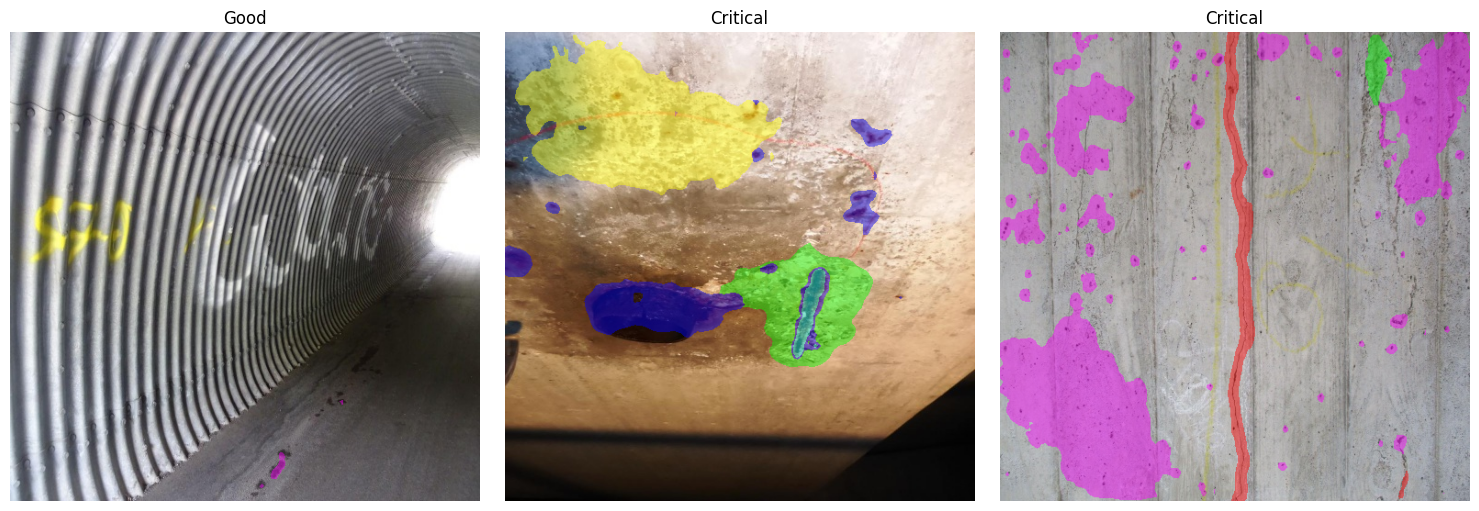

In [ ]:
COLORS = [(255,0,0),(0,255,0),(0,0,255),(255,255,0),(255,0,255),(0,255,255)]

@torch.no_grad()
def analyze(path):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    small = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    x = to_x(small); out = []
    for mdl in (model, dl):
        p  = torch.sigmoid(mdl(x))[0].float()
        pf = torch.flip(torch.sigmoid(mdl(torch.flip(x, [3]))), [3])[0].float()
        out.append((p + pf) / 2)
    masks = (((out[0] + out[1]) / 2).cpu().numpy() > thr[:, None, None]).astype(np.uint8)
    me = measures(masks); g = overall_grade(me)
    ov = small.copy()
    for c in range(NC): ov[masks[c] > 0] = COLORS[c]
    rep = {"overall": names[g], "crack_length": round(me["crack_L"], 2), "crack_width_px": round(me["crack_W"], 1),
           **{f"{n}_area_%": round(me[n] * 100, 2) for n in AREA_NAMES}}
    return cv2.addWeighted(small, .55, ov, .45, 0), rep

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, k in zip(ax, [5, 100, 400]):
    ov, rep = analyze(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg"))
    a.imshow(ov); a.axis("off"); a.set_title(rep["overall"]); print(k, rep)
plt.tight_layout(); plt.show()

In [ ]:
import gradio as gr, json
def run(img):
    cv2.imwrite("/content/tmp.jpg", cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    ov, rep = analyze("/content/tmp.jpg")
    rep = {k: (v if isinstance(v, str) else float(v)) for k, v in rep.items()}
    return ov, json.dumps(rep, indent=2)

demo = gr.Interface(run, gr.Image(type="numpy"),
    [gr.Image(label="Detected defects"), gr.Textbox(lines=12, label="Severity report")],
    title="Bridge defect analyzer",
    description="Colors: Crack red, Spalling green, Rust blue, Efflorescence yellow, Cavity magenta, ExposedRebars cyan")
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c8681baa680b95b34f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
ks = np.random.default_rng(3).choice(len(test_ids), 20, replace=False)
rows = []
for k in ks:
    _, rep = analyze(str(PROC/"test"/"img"/f"{test_ids[k]}.jpg"))
    rows.append({"image": test_ids[k], **{a: (b if isinstance(b, str) else float(b)) for a, b in rep.items()}})
summary = pd.DataFrame(rows); print(summary.to_string(index=False))
summary.to_csv(FIG/"inspection_summary_20.csv", index=False)

                     image  overall  crack_length  crack_width_px  Spalling_area_%  Rust_area_%  Efflorescence_area_%  Cavity_area_%  ExposedRebars_area_%
dacl10k_v2_validation_0775     Good          0.00             0.0             0.00         0.00                  0.00           0.00                  0.00
dacl10k_v2_validation_0770     Poor          0.00             0.0             0.00         2.18                  0.00           0.00                  0.00
dacl10k_v2_validation_0174     Fair          0.00             0.0             0.59         0.00                  0.00           0.00                  0.00
dacl10k_v2_validation_0418     Good          0.00             0.0             0.00         0.00                  0.00           0.00                  0.00
dacl10k_v2_validation_0227 Critical          0.47             8.1             0.00         0.00                  2.36          18.67                  0.00
dacl10k_v2_validation_0464 Critical          0.45             8.9     

In [ ]:
!pip list 2>/dev/null | grep -i -E "^(torch|torchvision|segmentation.models.pytorch|albumentations|opencv-python-headless|scikit-image|scikit-learn|pandas|numpy|matplotlib|seaborn|gradio) "

albumentations                        2.0.8
gradio                                6.31.0
matplotlib                            3.10.0
numpy                                 2.4.6
opencv-python-headless                5.0.0.93
pandas                                2.2.3
scikit-image                          0.25.2
scikit-learn                          1.6.1
seaborn                               0.13.2
torch                                 2.14.1+cu130
torchvision                           0.29.1+cu130


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls -lh /content/drive/MyDrive/bridge_project/figures

total 462K
-rw------- 1 root root 95K Nov  1 13:23  cooccurrence.png
-rw------- 1 root root 38K Nov  1 13:23  defect_size.png
-rw------- 1 root root 39K Nov  1 13:23  images_per_class.png
-rw------- 1 root root 73K Nov  1 13:23  polygons_per_class.png
-rw------- 1 root root 52K Nov  7 04:10 'test IoU per class.png'
-rw------- 1 root root 75K Nov  7 04:10 'training loss.png'
-rw------- 1 root root 90K Nov  7 04:10 'validation mIoU.png'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


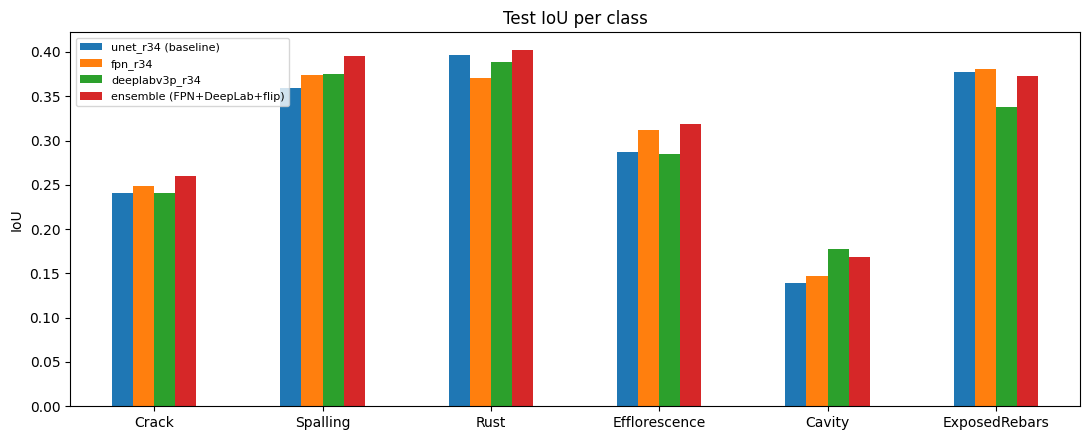

model
unet_r34 (baseline)            0.300
fpn_r34                        0.306
deeplabv3p_r34                 0.301
ensemble (FPN+DeepLab+flip)    0.320
dtype: float64
row sums (should be 35, 47, 81, 37): [35, 47, 81, 37]


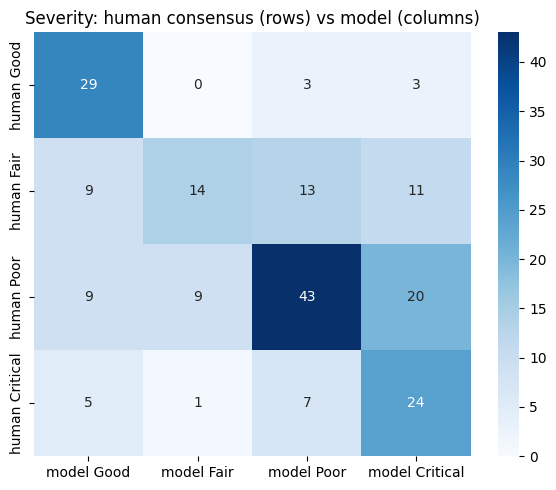

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
FIG = Path("/content/drive/MyDrive/bridge_experiments/figures")
TARGET = ["Crack","Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]

# 1) per-class test IoU, including the final ensemble
cmp = pd.read_csv(FIG/"model_comparison.csv").set_index("model")
ens = pd.read_csv(FIG/"ensemble_test_results.csv", index_col=0)
iou = cmp[TARGET].copy()
iou.loc["ensemble (FPN+DeepLab+flip)"] = ens["IoU"].reindex(TARGET).values
iou.T.plot(kind="bar", figsize=(11, 4.5)); plt.ylabel("IoU"); plt.title("Test IoU per class")
plt.xticks(rotation=0); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(FIG/"per_class_test_iou_final.png", dpi=150); plt.show()
print(iou.mean(axis=1).round(3))

# 2) severity: human consensus vs model
cm = pd.read_csv(FIG/"rating3_confusion_rules.csv", index_col=0)
print("row sums (should be 35, 47, 81, 37):", cm.sum(axis=1).tolist())
plt.figure(figsize=(6, 5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Severity: human consensus (rows) vs model (columns)"); plt.tight_layout()
plt.savefig(FIG/"severity_confusion_final.png", dpi=150); plt.show()

grading 200 rated images ...


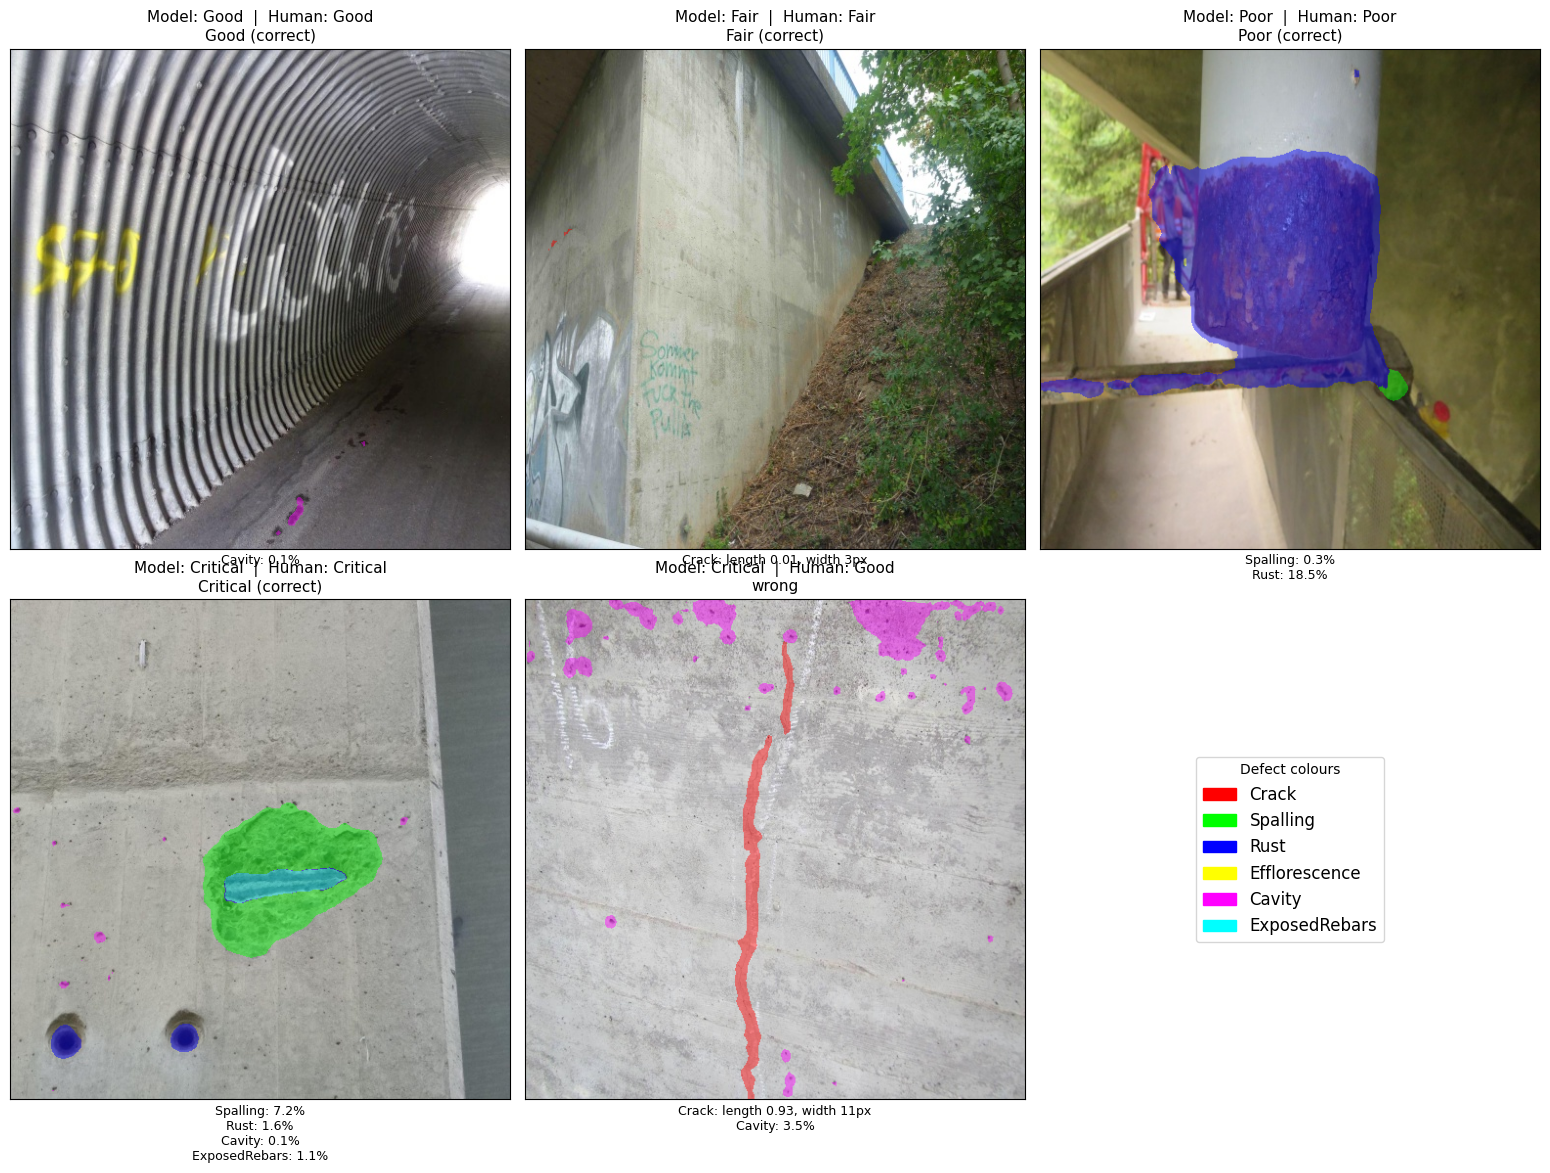

 panel                      image    human    model                tag
     1 dacl10k_v2_validation_0005     Good     Good     Good (correct)
     2 dacl10k_v2_validation_0152     Fair     Fair     Fair (correct)
     3 dacl10k_v2_validation_0895     Poor     Poor     Poor (correct)
     4 dacl10k_v2_validation_0312 Critical Critical Critical (correct)
     5 dacl10k_v2_validation_0594     Good Critical              wrong

Figure -> /content/drive/MyDrive/bridge_experiments/figures/demo_examples.png 
Original photos (to upload into the Gradio app) -> /content/drive/MyDrive/bridge_experiments/figures/demo_inputs


In [2]:
# ===== DEMO EXAMPLES: Good / Fair / Poor / Critical + one wrong case, in one figure =====
import os, json, warnings; warnings.filterwarnings("ignore")
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")
os.system("pip install -q segmentation-models-pytorch opencv-python-headless scikit-image")
if not os.path.exists("/content/processed"):
    os.system("unzip -q /content/drive/MyDrive/bridge_project/processed.zip -d /content/")

from pathlib import Path
import numpy as np, pandas as pd, cv2, torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import segmentation_models_pytorch as smp
from skimage.morphology import skeletonize

SEED = 11            # change this number to get different example images
PROC = Path("/content/processed"); BASE = Path("/content/drive/MyDrive/bridge_project")
EXP_ROOT = Path("/content/drive/MyDrive/bridge_experiments"); FIG = EXP_ROOT/"figures"; RATE3 = EXP_ROOT/"rating3"
TARGET = ["Crack","Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]; NC, SIZE = 6, 512
DEV = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = np.array([0.485,0.456,0.406]), np.array([0.229,0.224,0.225])
names = ["Good","Fair","Poor","Critical"]; lab = {n.lower(): i for i, n in enumerate(names)}
raters = ["Namitha","Jeevani","Gouthami","Vishnu"]
COLORS = [(255,0,0),(0,255,0),(0,0,255),(255,255,0),(255,0,255),(0,255,255)]
test_ids = sorted(p.stem for p in (PROC/"test"/"img").glob("*.jpg"))

# ---- final model: FPN + DeepLabV3+ with h-flip, saved thresholds ----
model = smp.FPN(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
model.load_state_dict(torch.load(BASE/"best_fpn.pth", map_location=DEV)); model.eval()
dl = smp.DeepLabV3Plus(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
dl.load_state_dict(torch.load(BASE/"best_deeplab.pth", map_location=DEV)); dl.eval()
thr_d = json.load(open(EXP_ROOT/"thresholds_ens_flip.json")); thr = np.array([thr_d[t] for t in TARGET])

def to_x(img): return torch.from_numpy(((img/255.0 - MEAN)/STD).transpose(2,0,1)).float()[None].to(DEV)
def load_img(k): return cv2.cvtColor(cv2.imread(str(PROC/"test"/"img"/f"{test_ids[int(k)]}.jpg")), cv2.COLOR_BGR2RGB)
@torch.no_grad()
def final_masks(k):
    x = to_x(load_img(k)); out = []
    for mdl in (model, dl):
        p  = torch.sigmoid(mdl(x))[0].float()
        pf = torch.flip(torch.sigmoid(mdl(torch.flip(x, [3]))), [3])[0].float()
        out.append((p + pf) / 2)
    return (((out[0] + out[1]) / 2).cpu().numpy() > thr[:, None, None]).astype(np.uint8)

# ---- severity rules (frozen, same as the paper) ----
AREA_CUTS = {"Spalling":(0.01,0.05),"Rust":(0.02,0.08),"Efflorescence":(0.03,0.10),"Cavity":(0.005,0.02),"ExposedRebars":(0.002,0.01)}
MIN_PX = {"Crack":20,"Spalling":150,"Rust":150,"Efflorescence":150,"Cavity":15,"ExposedRebars":60}
STRUCTURAL = {"Crack","Spalling","Cavity","ExposedRebars"}; AREA_NAMES = ["Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]
def clean_mask(m, mp):
    n, lb, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8); out = np.zeros(m.shape, np.uint8)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= mp: out[lb == i] = 1
    return out
def grade(v, c): return 0 if v <= 0 else 1 if v < c[0] else 2 if v < c[1] else 3
def crack_metrics(m):
    if m.sum() == 0: return 0.0, 0.0
    sk = skeletonize(m > 0); d = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 3); L = sk.sum()
    return L/SIZE, (2*d[sk].mean() if L else 0.0)
def measures(masks):
    o = {}
    for c, n in enumerate(TARGET):
        mm = clean_mask(masks[c], MIN_PX[n])
        if n == "Crack": o["crack_L"], o["crack_W"] = crack_metrics(mm)
        else: o[n] = float(mm.mean())
    return o
def overall_grade(me, bump_w=6, ff=0.25):
    g = grade(me["crack_L"], (0.3, 1.0))
    if g > 0 and me["crack_W"] > bump_w: g = min(3, g+1)
    c = [g]
    for n in AREA_NAMES:
        v = me[n]; gg = 0 if v < ff*AREA_CUTS[n][0] else grade(v, AREA_CUTS[n]); c.append(gg if n in STRUCTURAL else min(gg, 2))
    return max(c)

# ---- human consensus on the 200 rated images (rating3) ----
r3 = pd.read_csv(RATE3/"rating3.csv")
for c in raters: r3[c] = r3[c].astype(str).str.strip().str.lower().map(lab)
r3 = r3[r3[raters].notna().sum(axis=1) >= 2].copy()
df3 = r3.merge(pd.read_csv(FIG/"rating3_key_DO_NOT_SHARE.csv"), on="img_id").reset_index(drop=True)
y3 = np.floor(np.nanmedian(df3[raters].values.astype(float), axis=1) + 0.5).astype(int)
print("grading", len(df3), "rated images ...")
mg = np.array([overall_grade(measures(final_masks(k))) for k in df3.test_index])

# ---- choose examples: one correct case per grade + the biggest over-grade error ----
rng = np.random.default_rng(SEED); picks = []
for lv in range(4):
    ok = [i for i in range(len(df3)) if y3[i] == lv and mg[i] == lv]
    if ok: picks.append((int(rng.choice(ok)), f"{names[lv]} (correct)"))
gap = mg - y3
bad = [i for i in range(len(df3)) if gap[i] >= 1 and y3[i] <= 1] or [i for i in range(len(df3)) if gap[i] != 0]
if bad:
    top = [i for i in bad if gap[i] == max(gap[j] for j in bad)]
    picks.append((int(rng.choice(top)), "wrong"))

# ---- draw the figure (same overlay colours as the Gradio demo) ----
def report_lines(me):
    L = []
    if me["crack_L"] > 0: L.append(f"Crack: length {me['crack_L']:.2f}, width {me['crack_W']:.0f}px")
    for n in AREA_NAMES:
        if me[n] > 0: L.append(f"{n}: {me[n]*100:.1f}%")
    return L[:4] or ["No defects detected"]

OUTDIR = FIG/"demo_inputs"; OUTDIR.mkdir(parents=True, exist_ok=True)
ncols = 3; nrows = int(np.ceil((len(picks) + 1) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2*ncols, 5.8*nrows)); axes = axes.ravel()
rows = []
for ax, (i, tag) in zip(axes, picks):
    k = int(df3.test_index[i]); img = load_img(k); pm = final_masks(k); me = measures(pm)
    ov = img.copy()
    for c in range(NC): ov[pm[c] > 0] = COLORS[c]
    ax.imshow(cv2.addWeighted(img, .55, ov, .45, 0)); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"Model: {names[mg[i]]}  |  Human: {names[y3[i]]}\n{tag}", fontsize=11)
    ax.set_xlabel("\n".join(report_lines(me)), fontsize=9)
    cv2.imwrite(str(OUTDIR/f"{len(rows)+1}_{names[y3[i]]}_{tag.split()[0]}_{test_ids[k]}.jpg"), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
    rows.append(dict(panel=len(rows)+1, image=test_ids[k], human=names[y3[i]], model=names[mg[i]], tag=tag))
for ax in axes[len(picks):]: ax.axis("off")
axes[len(picks)].legend(handles=[Patch(color=np.array(c)/255, label=n) for c, n in zip(COLORS, TARGET)], loc="center", fontsize=12, title="Defect colours")
plt.tight_layout(); plt.savefig(FIG/"demo_examples.png", dpi=200); plt.show()
pd.DataFrame(rows).to_csv(FIG/"demo_examples.csv", index=False); print(pd.DataFrame(rows).to_string(index=False))
print("\nFigure ->", FIG/"demo_examples.png", "\nOriginal photos (to upload into the Gradio app) ->", OUTDIR)

In [6]:
# ===== GRADIO DEMO (self-contained) =====
import os, json, glob, warnings; warnings.filterwarnings("ignore")
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")
os.system("pip install -q gradio segmentation-models-pytorch opencv-python-headless scikit-image")

from pathlib import Path
import numpy as np, cv2, torch
import segmentation_models_pytorch as smp
from skimage.morphology import skeletonize
import gradio as gr

BASE = Path("/content/drive/MyDrive/bridge_project"); EXP_ROOT = Path("/content/drive/MyDrive/bridge_experiments")
TARGET = ["Crack","Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]; NC, SIZE = 6, 512
DEV = "cuda" if torch.cuda.is_available() else "cpu"
MEAN, STD = np.array([0.485,0.456,0.406]), np.array([0.229,0.224,0.225])
names = ["Good","Fair","Poor","Critical"]
COLORS = [(255,0,0),(0,255,0),(0,0,255),(255,255,0),(255,0,255),(0,255,255)]

model = smp.FPN(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
model.load_state_dict(torch.load(BASE/"best_fpn.pth", map_location=DEV)); model.eval()
dl = smp.DeepLabV3Plus(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=NC, activation=None).to(DEV)
dl.load_state_dict(torch.load(BASE/"best_deeplab.pth", map_location=DEV)); dl.eval()
thr_d = json.load(open(EXP_ROOT/"thresholds_ens_flip.json")); thr = np.array([thr_d[t] for t in TARGET])

AREA_CUTS = {"Spalling":(0.01,0.05),"Rust":(0.02,0.08),"Efflorescence":(0.03,0.10),"Cavity":(0.005,0.02),"ExposedRebars":(0.002,0.01)}
MIN_PX = {"Crack":20,"Spalling":150,"Rust":150,"Efflorescence":150,"Cavity":15,"ExposedRebars":60}
STRUCTURAL = {"Crack","Spalling","Cavity","ExposedRebars"}; AREA_NAMES = ["Spalling","Rust","Efflorescence","Cavity","ExposedRebars"]
def clean_mask(m, mp):
    n, lb, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8); out = np.zeros(m.shape, np.uint8)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= mp: out[lb == i] = 1
    return out
def grade(v, c): return 0 if v <= 0 else 1 if v < c[0] else 2 if v < c[1] else 3
def crack_metrics(m):
    if m.sum() == 0: return 0.0, 0.0
    sk = skeletonize(m > 0); d = cv2.distanceTransform(m.astype(np.uint8), cv2.DIST_L2, 3); L = sk.sum()
    return L/SIZE, (2*d[sk].mean() if L else 0.0)
def measures(masks):
    o = {}
    for c, n in enumerate(TARGET):
        mm = clean_mask(masks[c], MIN_PX[n])
        if n == "Crack": o["crack_L"], o["crack_W"] = crack_metrics(mm)
        else: o[n] = float(mm.mean())
    return o
def overall_grade(me, bump_w=6, ff=0.25):
    g = grade(me["crack_L"], (0.3, 1.0))
    if g > 0 and me["crack_W"] > bump_w: g = min(3, g+1)
    c = [g]
    for n in AREA_NAMES:
        v = me[n]; gg = 0 if v < ff*AREA_CUTS[n][0] else grade(v, AREA_CUTS[n]); c.append(gg if n in STRUCTURAL else min(gg, 2))
    return max(c)

def to_x(img): return torch.from_numpy(((img/255.0 - MEAN)/STD).transpose(2,0,1)).float()[None].to(DEV)
@torch.no_grad()
def run(img):
    if img is None: return None, "Upload a bridge photo first."
    small = cv2.resize(img, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    x = to_x(small); out = []
    for mdl in (model, dl):
        p  = torch.sigmoid(mdl(x))[0].float()
        pf = torch.flip(torch.sigmoid(mdl(torch.flip(x, [3]))), [3])[0].float()
        out.append((p + pf) / 2)
    masks = (((out[0] + out[1]) / 2).cpu().numpy() > thr[:, None, None]).astype(np.uint8)
    me = measures(masks); g = overall_grade(me)
    ov = small.copy()
    for c in range(NC): ov[masks[c] > 0] = COLORS[c]
    rep = {"overall": names[g], "crack_length": round(float(me["crack_L"]), 2), "crack_width_px": round(float(me["crack_W"]), 1),
           **{f"{n}_area_%": round(float(me[n]) * 100, 2) for n in AREA_NAMES}}
    return cv2.addWeighted(small, .55, ov, .45, 0), json.dumps(rep, indent=2)

# example photos: the ones saved by the earlier demo-examples cell, if you ran it
ex = sorted(glob.glob(str(EXP_ROOT/"figures"/"demo_inputs"/"*.jpg")))
demo = gr.Interface(run, gr.Image(type="numpy", label="Bridge photo"),
    [gr.Image(label="Detected defects"), gr.Textbox(lines=12, label="Severity report")],
    examples=[[p] for p in ex] or None,
    title="Bridge defect analyzer",
    description="Colors: Crack red, Spalling green, Rust blue, Efflorescence yellow, Cavity magenta, ExposedRebars cyan")
demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://5abdf9511deae89b09.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://5abdf9511deae89b09.gradio.live


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


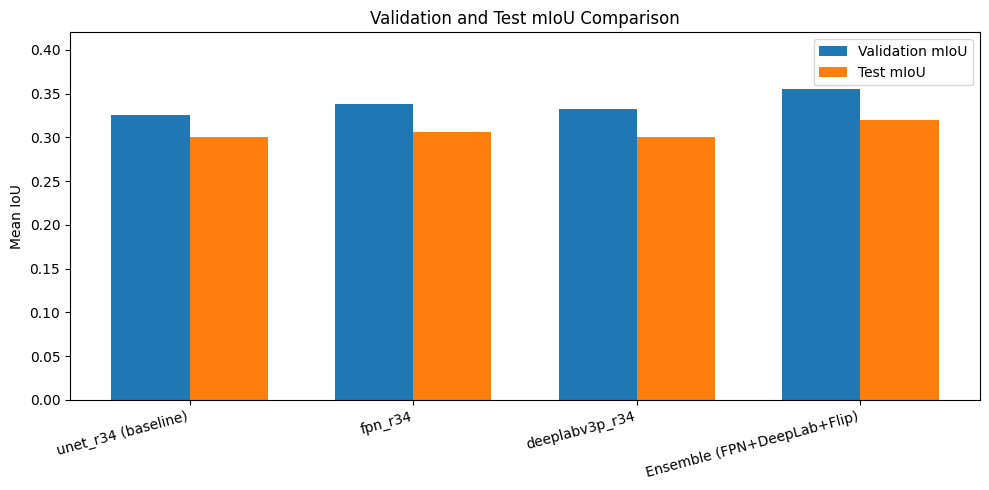

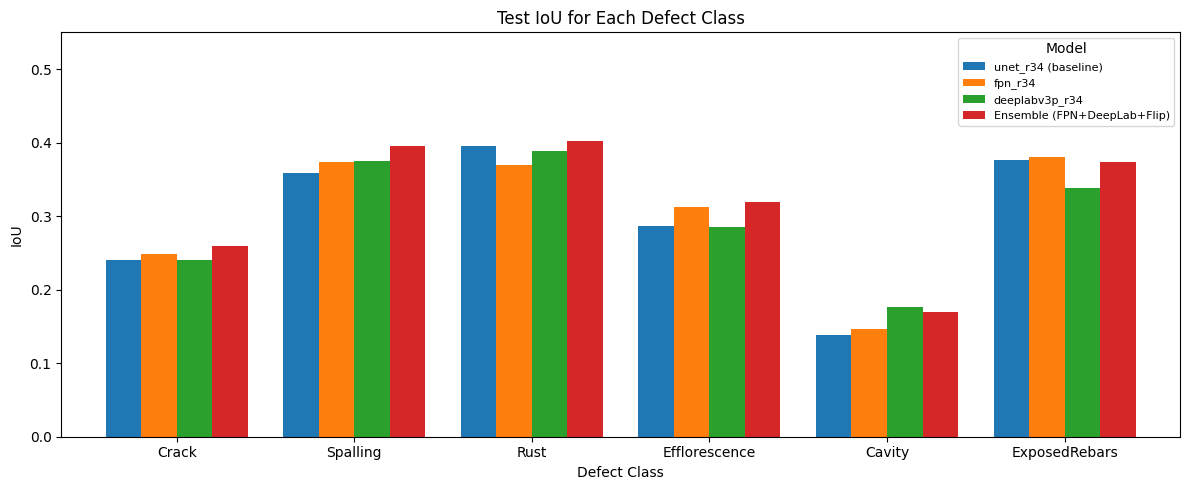

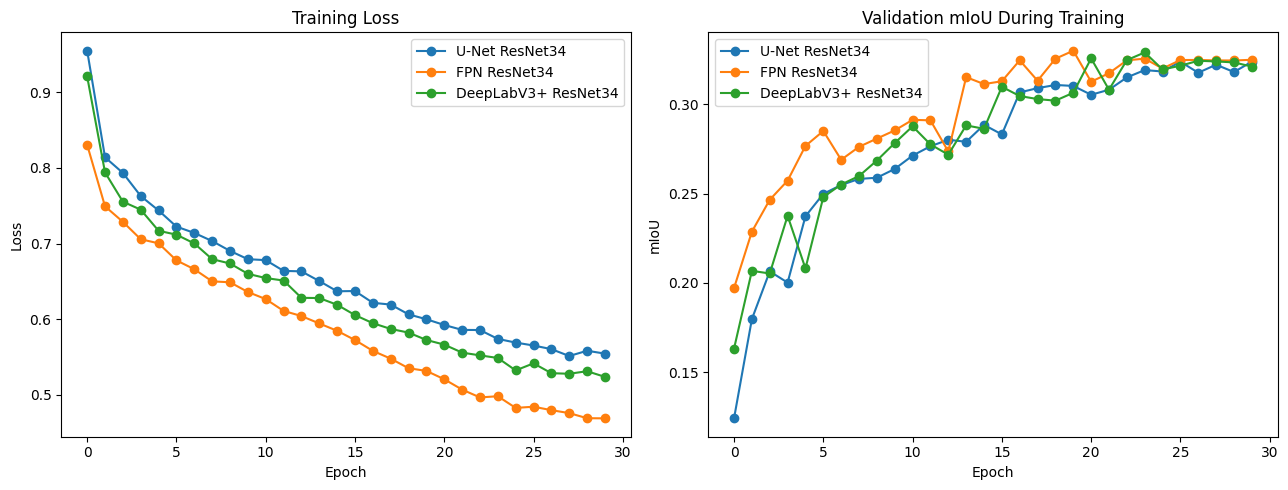

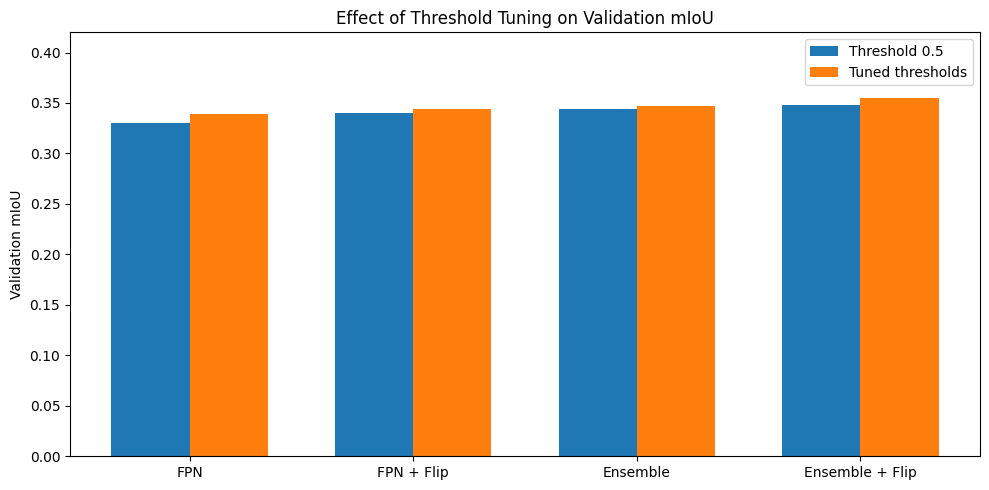

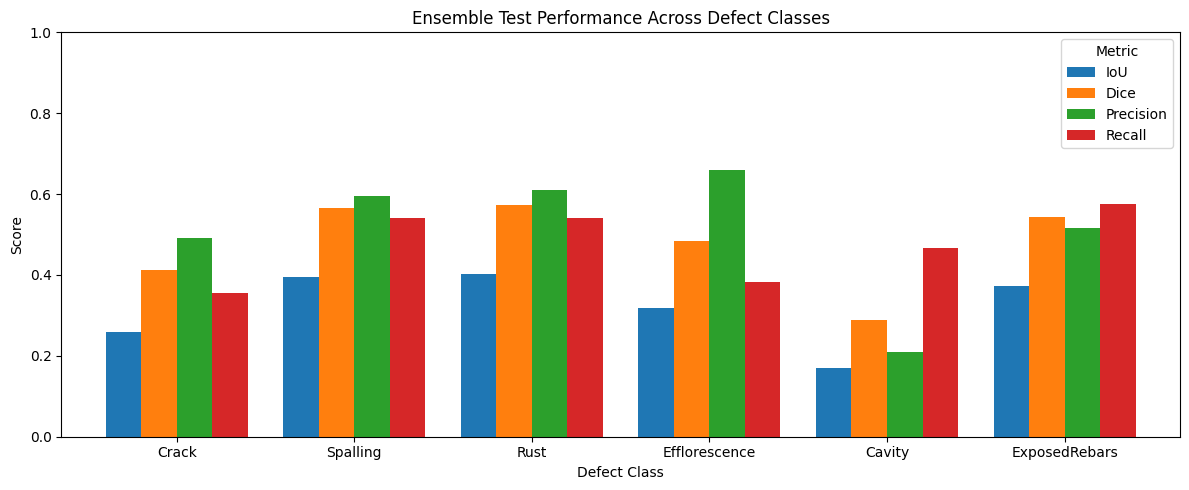

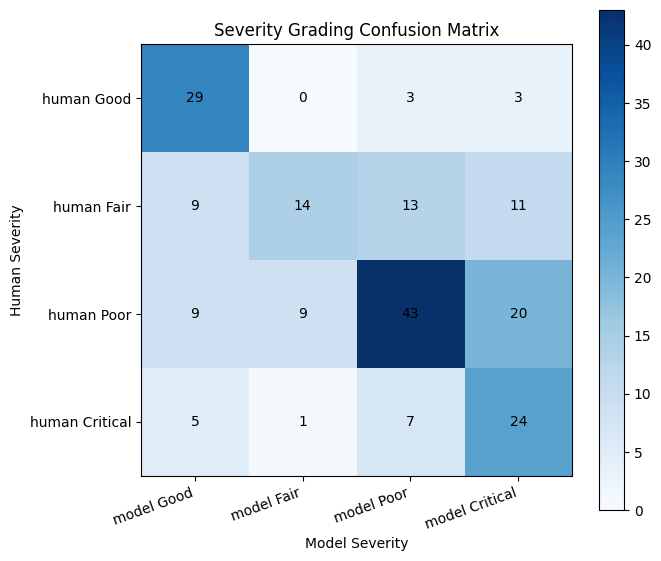

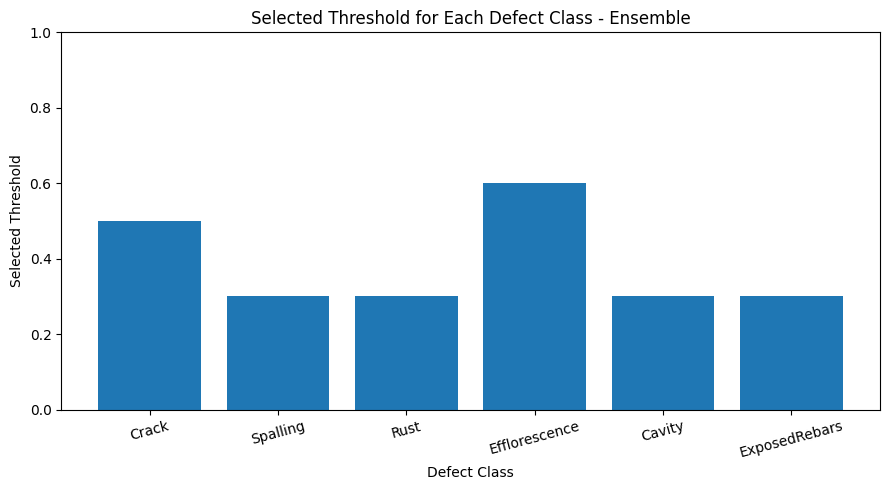


ALL AVAILABLE GRAPHS GENERATED SUCCESSFULLY!
Saved in: /content/drive/MyDrive/bridge_experiments/figures
graph1_model_comparison.png
graph2_per_class_test_iou.png
graph3_training_curves.png
graph4_threshold_tuning_validation.png
graph5_ensemble_test_metrics.png
graph6_severity_confusion_matrix.png
graph7_ensemble_thresholds.png


In [4]:

# ============================================================
# ONE-CELL CODE: GENERATE ALL REPORT GRAPHS
# Includes U-Net, FPN, DeepLabV3+ and Ensemble
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------- PATHS ----------------
BASE = Path("/content/drive/MyDrive/bridge_project")
EXP_ROOT = Path("/content/drive/MyDrive/bridge_experiments")
FIG = EXP_ROOT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

TARGET = [
    "Crack", "Spalling", "Rust",
    "Efflorescence", "Cavity", "ExposedRebars"
]

# ---------------- LOAD SAVED RESULTS ----------------
comparison = pd.read_csv(FIG / "model_comparison.csv")
ensemble = pd.read_csv(FIG / "ensemble_test_results.csv", index_col=0)

# Add ensemble test IoU to model comparison
ensemble_row = {
    "model": "Ensemble (FPN+DeepLab+Flip)",
    "val": 0.355,
    "test": 0.320
}

for cls in TARGET:
    ensemble_row[cls] = ensemble.loc[cls, "IoU"]

comparison = pd.concat(
    [comparison, pd.DataFrame([ensemble_row])],
    ignore_index=True
)

# ============================================================
# GRAPH 1: MODEL COMPARISON - VALIDATION AND TEST mIoU
# ============================================================

plt.figure(figsize=(10, 5))

x = np.arange(len(comparison))
width = 0.35

plt.bar(x - width/2, comparison["val"], width,
        label="Validation mIoU")

plt.bar(x + width/2, comparison["test"], width,
        label="Test mIoU")

plt.xticks(x, comparison["model"], rotation=15, ha="right")
plt.ylabel("Mean IoU")
plt.title("Validation and Test mIoU Comparison")
plt.ylim(0, 0.42)
plt.legend()
plt.tight_layout()

plt.savefig(FIG / "graph1_model_comparison.png", dpi=300)
plt.show()


# ============================================================
# GRAPH 2: PER-CLASS TEST IoU - ALL FOUR APPROACHES
# ============================================================

iou_data = comparison.set_index("model")[TARGET]

ax = iou_data.T.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

ax.set_title("Test IoU for Each Defect Class")
ax.set_ylabel("IoU")
ax.set_xlabel("Defect Class")
ax.set_ylim(0, 0.55)
plt.xticks(rotation=0)
plt.legend(title="Model", fontsize=8)
plt.tight_layout()

plt.savefig(FIG / "graph2_per_class_test_iou.png", dpi=300)
plt.show()


# ============================================================
# GRAPH 3: TRAINING LOSS AND VALIDATION mIoU
# Note: Ensemble has no separate training history.
# ============================================================

histories = {
    "U-Net ResNet34": BASE / "history.csv",
    "FPN ResNet34": BASE / "history_fpn.csv",
    "DeepLabV3+ ResNet34": BASE / "history_deeplab.csv"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, path in histories.items():
    if path.exists():
        h = pd.read_csv(path)

        axes[0].plot(
            h["epoch"], h["train_loss"],
            marker="o", label=name
        )

        axes[1].plot(
            h["epoch"], h["val_miou"],
            marker="o", label=name
        )
    else:
        print("Missing training history:", path)

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Validation mIoU During Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mIoU")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG / "graph3_training_curves.png", dpi=300)
plt.show()


# ============================================================
# GRAPH 4: VALIDATION mIoU BEFORE AND AFTER THRESHOLD TUNING
# Includes all four ensemble variants from notebook Cell 41.
# ============================================================

variants = [
    "FPN",
    "FPN + Flip",
    "Ensemble",
    "Ensemble + Flip"
]

val_default = [0.330, 0.340, 0.344, 0.348]
val_tuned = [0.339, 0.344, 0.347, 0.355]

x = np.arange(len(variants))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, val_default, width,
        label="Threshold 0.5")

plt.bar(x + width/2, val_tuned, width,
        label="Tuned thresholds")

plt.xticks(x, variants)
plt.ylabel("Validation mIoU")
plt.title("Effect of Threshold Tuning on Validation mIoU")
plt.ylim(0, 0.42)
plt.legend()
plt.tight_layout()

plt.savefig(FIG / "graph4_threshold_tuning_validation.png", dpi=300)
plt.show()


# ============================================================
# GRAPH 5: ENSEMBLE PER-CLASS TEST METRICS
# IoU, Dice, Precision and Recall
# ============================================================

metrics = ensemble[["IoU", "Dice", "Precision", "Recall"]]

ax = metrics.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

ax.set_title("Ensemble Test Performance Across Defect Classes")
ax.set_ylabel("Score")
ax.set_xlabel("Defect Class")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()

plt.savefig(FIG / "graph5_ensemble_test_metrics.png", dpi=300)
plt.show()


# ============================================================
# GRAPH 6: ENSEMBLE SEVERITY GRADING CONFUSION MATRIX
# Uses the saved final 200-image rating results, if available.
# ============================================================

cm_path = FIG / "rating3_confusion_rules.csv"

if cm_path.exists():
    cm = pd.read_csv(cm_path, index_col=0)

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm.values, cmap="Blues")

    ax.set_xticks(range(len(cm.columns)))
    ax.set_yticks(range(len(cm.index)))
    ax.set_xticklabels(cm.columns, rotation=20, ha="right")
    ax.set_yticklabels(cm.index)

    ax.set_xlabel("Model Severity")
    ax.set_ylabel("Human Severity")
    ax.set_title("Severity Grading Confusion Matrix")

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm.iloc[i, j]),
                    ha="center", va="center")

    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.savefig(FIG / "graph6_severity_confusion_matrix.png", dpi=300)
    plt.show()
else:
    print("Severity confusion matrix CSV not found; skipping Graph 6.")


# ============================================================
# GRAPH 7: ENSEMBLE CHOSEN THRESHOLDS
# ============================================================

threshold_path = EXP_ROOT / "thresholds_ens_flip.json"

if threshold_path.exists():
    with open(threshold_path) as f:
        thresholds = json.load(f)

    plt.figure(figsize=(9, 5))
    plt.bar(thresholds.keys(), thresholds.values())

    plt.title("Selected Threshold for Each Defect Class - Ensemble")
    plt.xlabel("Defect Class")
    plt.ylabel("Selected Threshold")
    plt.ylim(0, 1)

    plt.xticks(rotation=15)
    plt.tight_layout()

    plt.savefig(FIG / "graph7_ensemble_thresholds.png", dpi=300)
    plt.show()
else:
    print("Ensemble threshold JSON not found; skipping Graph 7.")


# ---------------- FINAL OUTPUT ----------------
print("\nALL AVAILABLE GRAPHS GENERATED SUCCESSFULLY!")
print("Saved in:", FIG)

for file in sorted(FIG.glob("graph*.png")):
    print(file.name)
